<center><h1>Soundalgekar_Abhishek_HW4</h1></center>
<br>
<br>

Name: Abhishek Soundalgekar
<br>
Github Username: ABHISHEKSOUNDALGEKAR
<br>
USC ID: 2089011000

- - -

In [1]:
pip install -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### 1 (a) Obtain Data

Import packages

In [2]:
import os
import math
import glob
import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Stats and statistical models
import statsmodels.api as sm

# Bootstrapping
import bootstrapped.bootstrap as bs
import bootstrapped.stats_functions as bs_stats

# Scikit-learn modules
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import StratifiedKFold, train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_selection import RFECV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.metrics import (
    accuracy_score, 
    confusion_matrix, 
    roc_curve, 
    auc, 
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.utils import resample

Get the AReM Data Set

In [3]:

def list_all_files_recursive(folder_path: Path, indent: int = 0):
    prefix = "    " * indent
    for item in sorted(folder_path.iterdir()):
        if item.is_dir():
            print(f"{prefix} {item.name}/")
            list_all_files_recursive(item, indent + 1)
        elif item.is_file():
            print(f"{prefix} {item.name}")

if __name__ == "__main__":
    list_all_files_recursive(Path("../data/ARem"))


 .DS_Store
 bending1/
     dataset1.csv
     dataset2.csv
     dataset3.csv
     dataset4.csv
     dataset5.csv
     dataset6.csv
     dataset7.csv
 bending2/
     dataset1.csv
     dataset2.csv
     dataset3.csv
     dataset4.csv
     dataset5.csv
     dataset6.csv
 bendingType.pdf
 cycling/
     dataset1.csv
     dataset10.csv
     dataset11.csv
     dataset12.csv
     dataset13.csv
     dataset14.csv
     dataset15.csv
     dataset2.csv
     dataset3.csv
     dataset4.csv
     dataset5.csv
     dataset6.csv
     dataset7.csv
     dataset8.csv
     dataset9.csv
 lying/
     dataset1.csv
     dataset10.csv
     dataset11.csv
     dataset12.csv
     dataset13.csv
     dataset14.csv
     dataset15.csv
     dataset2.csv
     dataset3.csv
     dataset4.csv
     dataset5.csv
     dataset6.csv
     dataset7.csv
     dataset8.csv
     dataset9.csv
 sensorsPlacement.pdf
 sitting/
     dataset1.csv
     dataset10.csv
     dataset11.csv
     dataset12.csv
     dataset13.csv
     dataset14.csv
 

### 1 (b) Keep datasets 1 and 2 in folders bending1 and bending 2, as well as datasets 1, 2, and 3 in other folders as test data and other datasets as train data.

In [4]:
def read_csv_flexible(path: Path, skiprows: int = 4) -> pd.DataFrame:
    return pd.read_csv(
        path,
        skiprows=skiprows,
        engine="python",
        on_bad_lines="skip"
    )

def load_indices(folder: Path) -> list[int]:
    return sorted(
        int(p.stem.replace("dataset", ""))
        for p in folder.glob("dataset*.csv")
    )

def report_bad_rows(root_dir: str = ".", data_subdir: str = "data/ARem"):
    def count_rows(path: Path, skiprows: int = 4):
        with open(path, "r", encoding="utf-8") as f:
            lines = [line for line in f if line.strip()]
        total_data_rows = len(lines) - skiprows - 1
        actual_df = pd.read_csv(
            path,
            skiprows=skiprows,
            engine="python",
            on_bad_lines="skip"
        )
        return total_data_rows, len(actual_df)

    root = Path(root_dir) / data_subdir
    mismatches = []
    for folder in root.iterdir():
        if not folder.is_dir():
            continue
        for csv in folder.glob("dataset*.csv"):
            expected, actual = count_rows(csv)
            if expected != actual:
                mismatches.append((csv, expected, actual))

    if mismatches:
        print("Files with row mismatches:")
        for fn, exp, act in mismatches:
            print(f"  • {fn}: expected {exp} rows but read {act}")
    else:
        print("All files have consistent row counts.")

def prepare_ar_em(root_dir: str = ".", data_subdir: str = "data/ARem"):
    root = Path(root_dir) / data_subdir

    special = {"bending1": [1, 2], "bending2": [1, 2]}
    default_test = [1, 2, 3]

    train_parts, test_parts = [], []

    for folder in root.iterdir():
        if not folder.is_dir():
            continue
        activity = folder.name
        all_idxs = load_indices(folder)

        test_idxs  = special.get(activity, default_test)
        train_idxs = [i for i in all_idxs if i not in test_idxs]

        df_test = pd.concat(
            (read_csv_flexible(folder / f"dataset{i}.csv") for i in test_idxs),
            ignore_index=True
        )
        df_test["activity"] = activity

        df_train = pd.concat(
            (read_csv_flexible(folder / f"dataset{i}.csv") for i in train_idxs),
            ignore_index=True
        )
        df_train["activity"] = activity

        test_parts.append(df_test)
        train_parts.append(df_train)

    train_df = pd.concat(train_parts, ignore_index=True)
    test_df  = pd.concat(test_parts,  ignore_index=True)
    return train_df, test_df

if __name__ == "__main__":
    report_bad_rows(root_dir="..")
    train_df, test_df = prepare_ar_em(root_dir="..")
    train_df = train_df.drop(columns="activity")
    test_df  = test_df.drop(columns="activity")
    print(f"Train shape: {train_df.shape}")
    print(f"Test  shape: {test_df.shape}")
    print("*******************************************************************************")
    print(f"Train data: \n{train_df}")
    print("*******************************************************************************")

    print(f"Test data: \n{test_df}")
    print("*******************************************************************************")


All files have consistent row counts.
Train shape: (33119, 7)
Test  shape: (9120, 7)
*******************************************************************************
Train data: 
       # Columns: time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  \
0                    0      42.00       0.71      21.25       0.43      30.00   
1                  250      41.50       0.50      20.25       1.48      31.25   
2                  500      41.50       0.50      14.25       1.92      33.00   
3                  750      40.75       0.83      15.75       0.43      33.00   
4                 1000      40.00       0.71      20.00       2.74      32.75   
...                ...        ...        ...        ...        ...        ...   
33114           118750      38.00       2.55      18.25       2.17      20.00   
33115           119000      36.00       0.00      19.00       1.41      13.67   
33116           119250      37.00       1.73      17.75       0.43      22.50   
33117       

### 1. (c) Feature Extraction
### Classification of time series usually needs extracting features from them. In this problem, we focus on time-domain features

#### 1] (c) (i) Research what types of time-domain features are usually used in time series classification and list them

* **Central Tendency & Quantiles**: Mean and median provide average and central values, while quantiles (e.g., 25th, 75th percentiles) capture distribution thresholds.

* **Range & Dispersion**: Minimum, maximum, and range (max–min) indicate signal extremes; standard deviation and variance measure overall spread, with coefficient of variation normalizing by mean.

* **Distribution Shape**: Skewness quantifies asymmetry around the mean, and kurtosis reflects tail heaviness.

* **Temporal Dynamics**: Autocorrelation at lagged intervals reveals repetitive patterns or memory, while zero-crossing rate counts sign changes indicating oscillation.

* **Peak-Related Measures**: Peak-to-peak amplitude measures maximum excursion between peaks and troughs; peak counts track local maxima frequency.

* **Stationarity & Complexity**: The Augmented Dickey–Fuller (ADF) test assesses series stationarity, while entropy metrics like sample entropy quantify signal irregularity.


#### 1] (c) (ii) Extract the time-domain features minimum, maximum, mean, median, standard deviation, first quartile, and third quartile for all of the 6 time series in each instance. You are free to normalize/standardize features or use them directly

In [5]:
def read_csv_flexible(path: Path, skiprows: int = 4) -> pd.DataFrame:
    return pd.read_csv(
        path,
        skiprows=skiprows,
        engine="python",
        on_bad_lines="skip"
    )

def extract_time_features(folder: Path,
                          activity: str,
                          start_instance: int,
                          series_cols: list[str]) -> tuple[list[list], int]:
    if activity == "bending1":
        num_files = 7
    elif activity == "bending2":
        num_files = 6
    else:
        num_files = 15

    data_rows = []
    for i in range(1, num_files + 1):
        file_path = folder / f"dataset{i}.csv"
        df = read_csv_flexible(file_path)

        features_df = [start_instance]
        for j, col in enumerate(series_cols):
            col_data = df[col]
            features_df.append(col_data.min())
            features_df.append(col_data.max())
            features_df.append(col_data.mean())
            features_df.append(col_data.median())
            features_df.append(col_data.std())
            features_df.append(col_data.quantile(0.25))
            features_df.append(col_data.quantile(0.75))
        data_rows.append(features_df)
        start_instance += 1

    return data_rows, start_instance

if __name__ == "__main__":
    data_root = Path("..") / "data" / "ARem"
    series = ["avg_rss12", "var_rss12",
              "avg_rss13", "var_rss13",
              "avg_rss23", "var_rss23"]

    all_data = []
    instance_id = 1

    for activity_folder in sorted(data_root.iterdir()):
        if activity_folder.is_dir():
            activity = activity_folder.name
            extracted_rows, instance_id = extract_time_features(
                activity_folder, activity, instance_id, series
            )
            all_data.extend(extracted_rows)

    stats = ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]
    headers = ["instance"]
    for i in range(6):
        for stat in stats:
            headers.append(f"{stat}{i+1}")
    
    df = pd.DataFrame(all_data, columns=headers)

    output_csv = data_root / "time_series_features.csv"
    df.to_csv(output_csv, index=False)
    pd.set_option('display.max_rows', 100)  # or more than 88

    print(f" New Dataset at: {output_csv}")
    print(df.head(88))
    
    # just added in-case to open the CSV file.
    try:
        os.startfile(output_csv)
    except AttributeError:
        os.system(f"open {output_csv}")

 New Dataset at: ../data/ARem/time_series_features.csv
    instance   min1   max1      mean1  median1      std1  1st_quart1  \
0          1  37.25  45.00  40.624792   40.500  1.476967     39.2500   
1          2  38.00  45.67  42.812812   42.500  1.435550     42.0000   
2          3  35.00  47.40  43.954500   44.330  1.558835     43.0000   
3          4  33.00  47.75  42.179812   43.500  3.670666     39.1500   
4          5  33.00  45.75  41.678063   41.750  2.243490     41.3300   
5          6  37.00  48.00  43.454958   43.250  1.386098     42.5000   
6          7  36.25  48.00  43.969125   44.500  1.618364     43.3100   
7          8  12.75  51.00  24.562958   24.250  3.737514     23.1875   
8          9   0.00  42.75  27.464604   28.000  3.583582     25.5000   
9         10  21.00  50.00  32.586208   33.000  6.238143     26.1875   
10        11  27.50  33.00  29.881938   30.000  1.153837     29.0000   
11        12  19.00  45.50  30.938104   29.000  7.684146     26.7500   
12       

### 1] C] (iii) Estimate the standard deviation of each of the time-domain features you extracted from the data. Then, use Python’s bootstrapped or any other method to build a 90% bootsrap confidence interval for the standard deviation of each feature.


Standard Deviations and 90% Bootstrap CIs:

            Std Dev  CI Lower  CI Upper
min1         9.5700    8.2360   10.7739
max1         4.3944    3.3399    5.2931
mean1        5.3357    4.7038    5.8758
median1      5.4401    4.7840    6.0063
std1         1.7722    1.5694    1.9495
1st_quart1   6.1536    5.5738    6.6486
3rd_quart1   5.1389    4.3386    5.8340
min2         0.0000    0.0000    0.0000
max2         5.0627    4.6306    5.4011
mean2        1.5742    1.3963    1.7056
median2      1.4122    1.2380    1.5441
std2         0.8841    0.8015    0.9425
1st_quart2   0.9464    0.8292    1.0347
3rd_quart2   2.1253    1.8932    2.2966
min3         2.9565    2.7563    3.1118
max3         4.8751    4.1548    5.4696
mean3        4.0084    3.4069    4.4985
median3      4.0364    3.4220    4.5447
std3         0.9467    0.7628    1.1231
1st_quart3   4.2207    3.6264    4.7090
3rd_quart3   4.1716    3.5399    4.6987
min4         0.0000    0.0000    0.0000
max4         2.1836    1.9708    2.

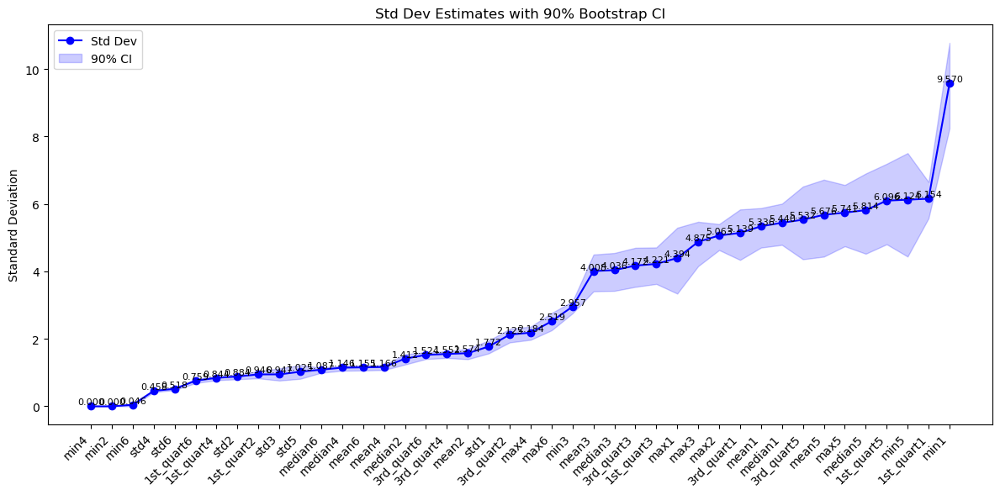

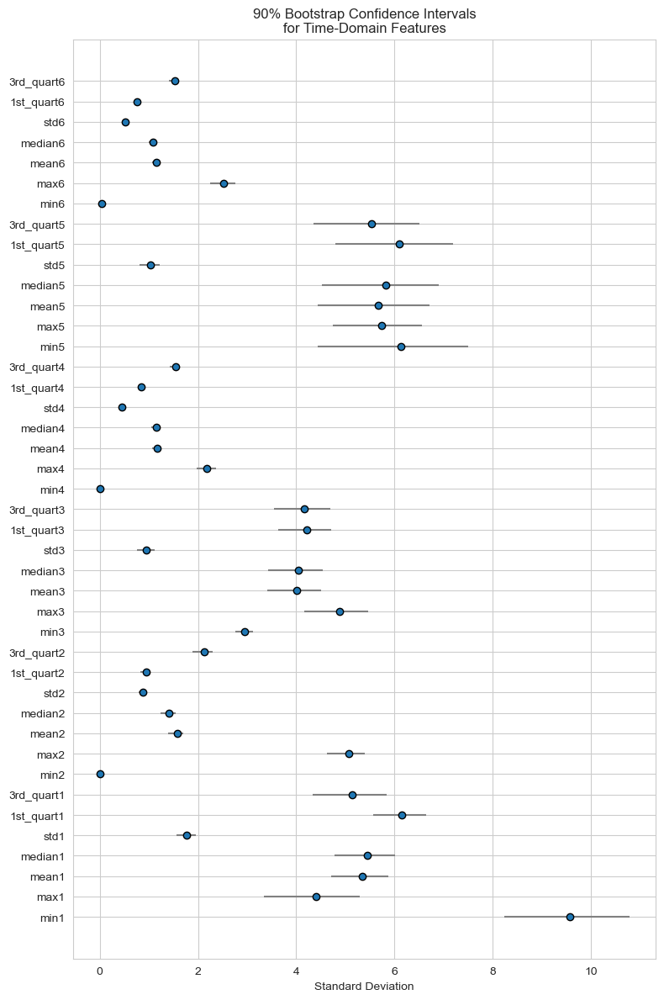

In [6]:
data_root = Path("..") / "data" / "ARem"
df = pd.read_csv(data_root / "time_series_features.csv")
exclude = {"Activity", "activity", "Instance", "instance"}
features = [col for col in df.columns if col not in exclude]
df[features] = df[features].apply(pd.to_numeric, errors='coerce')

#Bootstrap Function
def calculate_std_ci(data, iterations=10000, confidence=0.90, random_state=42):
    rng = np.random.default_rng(random_state)
    n = len(data)
    samples = rng.choice(data, size=(iterations, n), replace=True)
    boot_stds = samples.std(axis=1, ddof=1)
    low, high = np.percentile(boot_stds, [(1 - confidence)/2 * 100, (1 + confidence)/2 * 100])
    return data.std(ddof=1), (low, high)

#Bootstrap to all features
stats = {
    feat: calculate_std_ci(df[feat].dropna().to_numpy())
    for feat in features
}

df_stats = pd.DataFrame({
    k: {
        "Std Dev": round(v[0], 4),
        "CI Lower": round(v[1][0], 4),
        "CI Upper": round(v[1][1], 4)
    }
    for k, v in stats.items()
}).T

print("\nStandard Deviations and 90% Bootstrap CIs:\n")
print(df_stats)

#Line + Ribbon Plot
df_sorted = df_stats.sort_values("Std Dev")
x = np.arange(len(df_sorted))
y = df_sorted["Std Dev"].values
ci_low = df_sorted["CI Lower"].values
ci_high = df_sorted["CI Upper"].values

plt.figure(figsize=(12, 6))
plt.plot(x, y, marker="o", color="blue", label="Std Dev")
plt.fill_between(x, ci_low, ci_high, color="blue", alpha=0.2, label="90% CI")
for i, val in enumerate(y):
    plt.text(i, val, f"{val:.3f}", ha="center", va="bottom", fontsize=8)

plt.xticks(x, df_sorted.index, rotation=45, ha="right")
plt.ylabel("Standard Deviation")
plt.title("Std Dev Estimates with 90% Bootstrap CI")
plt.legend()
plt.tight_layout()
plt.show()

#Horizontal Error Bar Plot
features = df_stats.index.tolist()
stds = df_stats["Std Dev"].tolist()
lower_err = [s - l for s, l in zip(stds, df_stats["CI Lower"])]
upper_err = [u - s for s, u in zip(stds, df_stats["CI Upper"])]

plt.figure(figsize=(8, 12))
sns.set_style("whitegrid")
plt.errorbar(stds, features, xerr=[lower_err, upper_err], fmt='o',
             ecolor='gray', markeredgecolor='black')
plt.xlabel("Standard Deviation")
plt.title("90% Bootstrap Confidence Intervals\nfor Time-Domain Features")
plt.tight_layout()
plt.show()


### 1] (c) (iv) Use your judgement to select the three most important time-domain features(one option may be min, mean, and max)

I would choose **mean**, **max**, and **standard deviation** as the three most important features. Here's why each feature is significant:

1. **Mean**: The mean represents the average level of activity in the time series data, providing a baseline understanding of the signal's typical magnitude. It's crucial for distinguishing different activities based on their overall intensity.

2. **Max**: Maximum value identifies peak activity or spikes in the signal, effectively capturing outliers and extreme values that could indicate significant events or movements.

3. **Standard Deviation**: Standard deviation measures the variability or spread of the data points around the mean. It's valuable in identifying non-stationary activities such as walking or cycling, where the data fluctuates more widely.

These features together offer a comprehensive view of the signal's behavior, combining measures of central tendency (mean), extreme values (max), and variability (standard deviation). They are well-suited for tasks like classification or anomaly detection due to their ability to capture both the typical and exceptional aspects of the time series data.

- - -

### 2. Time Series Classification Part 2: Binary and Multiclass Classification

### 2.(a) Binary Classification Using Logistic Regression


#### 2. (a) i. Assume that you want to use the training set to classify bending from other activities, i.e. you have a binary classification problem. Depict scatter plots of the features you specified in 1(c)iv extracted from time series 1, 2, and 6 of each instance, and use color to distinguish bending vs. other activities. (See p. 129 of the textbook).

Full Time-Series Features (Training Set):


,Activity,Instance,min_1,max_1,mean_1,median_1,std-dev_1,1st quart_1,3rd quart_1,min_2,...,std-dev_5,1st quart_5,3rd quart_5,min_6,max_6,mean_6,median_6,std-dev_6,1st quart_6,3rd quart_6
0,bending1,1,35.00,47.40,43.954500,44.330,1.558835,43.0000,45.0000,0.0,...,1.999604,35.3625,36.5000,0.00,1.79,0.493292,0.430,0.513506,0.0000,0.9400
1,bending1,2,33.00,47.75,42.179812,43.500,3.670666,39.1500,45.0000,0.0,...,3.849448,30.4575,36.3300,0.00,2.18,0.613521,0.500,0.524317,0.0000,1.0000
2,bending1,3,33.00,45.75,41.678063,41.750,2.243490,41.3300,42.7500,0.0,...,2.411026,28.4575,31.2500,0.00,1.79,0.383292,0.430,0.389164,0.0000,0.5000
3,bending1,4,37.00,48.00,43.454958,43.250,1.386098,42.5000,45.0000,0.0,...,2.488862,22.2500,24.0000,0.00,5.26,0.679646,0.500,0.622534,0.4300,0.8700
4,bending1,5,36.25,48.00,43.969125,44.500,1.618364,43.3100,44.6700,0.0,...,3.318301,20.5000,23.7500,0.00,2.96,0.555312,0.490,0.487826,0.0000,0.8300
5,bending2,6,21.00,50.00,32.586208,33.000,6.238143,26.1875,34.5000,0.0,...,5.032424,17.6700,23.5000,0.00,13.61,1.162042,0.830,1.332980,0.4700,1.3000
6,bending2,7,27.50,33.00,29.881938,30.000,1.153837,29.0000,30.2700,0.0,...,1.745970,17.0000,19.0000,0.00,6.40,0.701625,0.710,0.481103,0.4700,0.9400
7,bending2,8,19.00,45.50,30.938104,29.000,7.684146,26.7500,38.0000,0.0,...,5.845911,15.0000,20.8125,0.00,6.73,1.107354,0.830,1.080842,0.4700,1.3000
8,bending2,9,25.00,47.50,31.058250,29.710,4.829794,27.5000,31.8125,0.0,...,7.853427,9.0000,18.3125,0.00,4.92,1.098104,0.940,0.831480,0.5000,1.3000
9,cycling,10,19.00,44.00,36.228396,36.000,3.528617,34.0000,39.0000,0.0,...,3.166655,14.0000,18.0625,0.00,9.98,3.480688,3.340,1.827769,2.1025,4.5500


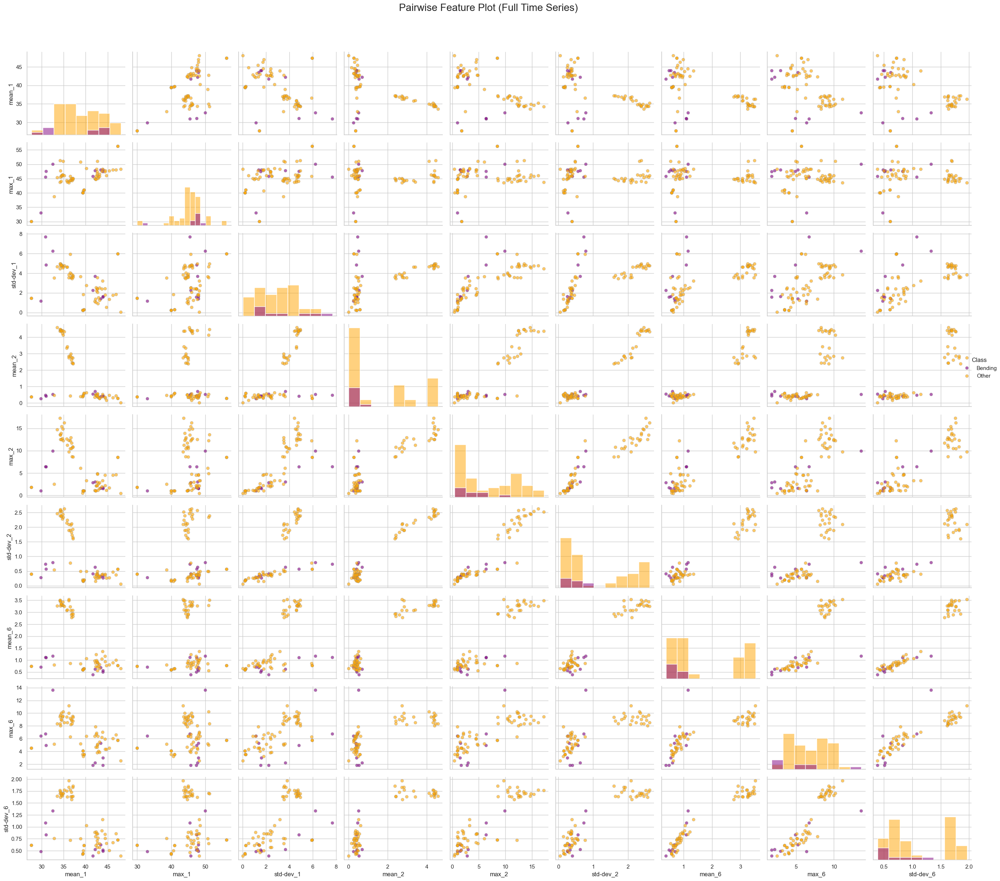

Split-Half Time-Series Features (Training Set):


,Activity,Instance,min_1_part1,max_1_part1,mean_1_part1,median_1_part1,std-dev_1_part1,1st quart_1_part1,3rd quart_1_part1,min_2_part1,...,std-dev_5_part2,1st quart_5_part2,3rd quart_5_part2,min_6_part2,max_6_part2,mean_6_part2,median_6_part2,std-dev_6_part2,1st quart_6_part2,3rd quart_6_part2
0,bending1,70,36.50,46.50,44.057167,44.500,1.556971,43.2500,45.0000,0.0,...,2.298693,33.0000,36.2500,0.00,1.50,0.388333,0.000,0.478528,0.0000,0.7100
1,bending1,71,33.75,47.75,43.278875,45.000,3.473355,42.0000,45.2500,0.0,...,3.760118,28.7500,33.7500,0.00,2.18,0.586083,0.470,0.491873,0.0000,0.8700
2,bending1,72,33.00,45.75,41.621208,42.330,3.118644,39.6525,44.2500,0.0,...,2.062647,28.3100,30.5625,0.00,1.50,0.347500,0.430,0.363144,0.0000,0.5000
3,bending1,73,39.00,48.00,44.117042,45.000,1.359836,43.5000,45.0000,0.0,...,1.881721,22.5000,23.7500,0.00,4.06,0.543875,0.500,0.473445,0.4300,0.7100
4,bending1,74,36.67,45.00,43.486208,43.710,1.281976,42.3300,44.5000,0.0,...,1.929494,21.0000,23.5000,0.00,2.96,0.585750,0.500,0.487918,0.4225,0.8300
5,bending2,75,21.00,50.00,32.014375,26.125,8.743464,24.7300,42.0000,0.0,...,2.994501,16.9375,20.0000,0.00,6.02,0.786042,0.710,0.768408,0.4700,0.9400
6,bending2,76,29.00,33.00,30.712417,30.290,0.937965,30.0000,31.5000,0.0,...,1.330388,17.3300,19.2500,0.00,1.50,0.677917,0.710,0.322210,0.4700,0.9400
7,bending2,77,19.00,39.25,29.189875,27.000,6.216895,25.9375,36.0000,0.0,...,7.166222,14.4575,25.0000,0.00,5.61,1.114917,0.870,0.996452,0.4700,1.3000
8,bending2,78,25.00,47.50,34.110625,30.500,5.097232,30.0000,39.3725,0.0,...,3.684946,8.3300,13.7500,0.00,4.92,1.199958,1.000,0.838177,0.7100,1.4100
9,cycling,79,26.00,44.00,36.183208,35.750,3.324873,34.0000,38.8125,0.0,...,3.273896,14.1500,18.6700,0.00,8.61,3.475333,3.340,1.861694,2.0500,4.5075


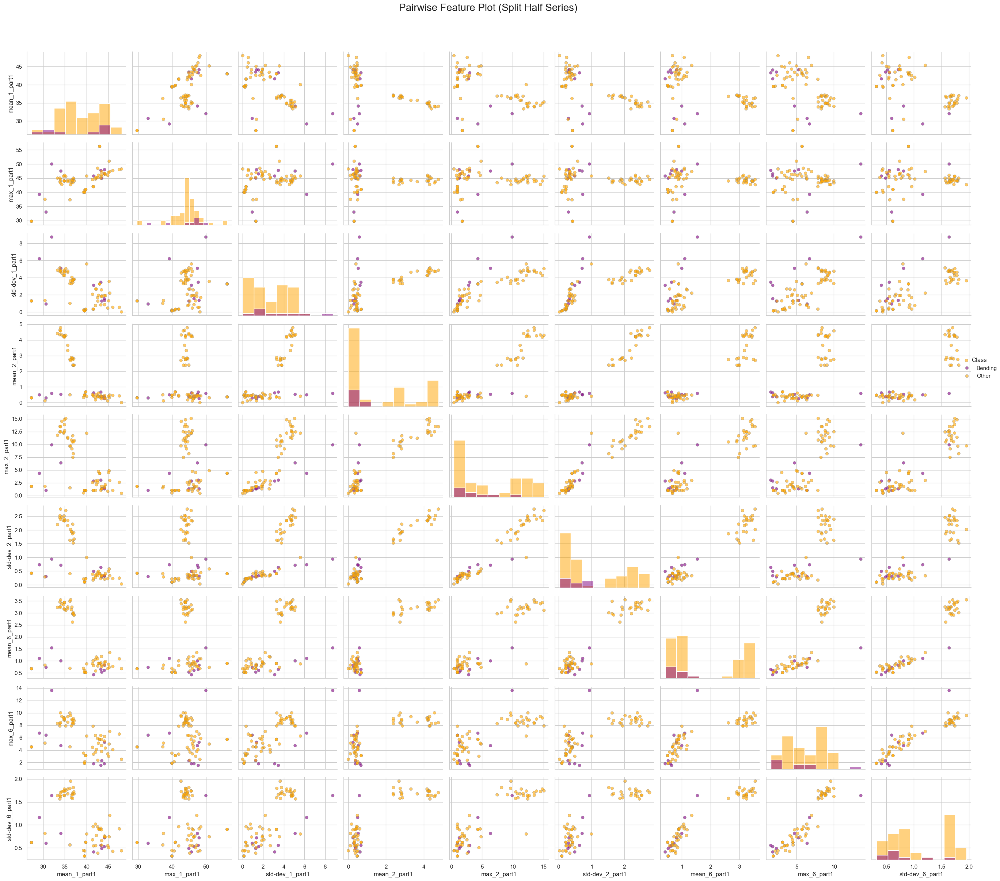

In [7]:
class FeatureExtractor:
    def __init__(self, data_path: Path):
        self.data_path = data_path
        self.activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
        self.sensors = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
        self.stats = ['min', 'max', 'mean', '50%', 'std', '25%', '75%']
        self.instance_id = 0

    def _read_dataset(self, activity: str, file_index: int) -> pd.DataFrame:
        return pd.read_csv(self.data_path / activity / f"dataset{file_index}.csv", skiprows=4)

    def _extract_stats(self, df: pd.DataFrame) -> list[float]:
        return [df[sensor].describe()[stat] for sensor in self.sensors for stat in self.stats]

    def extract_train_features(self, split: bool = False) -> pd.DataFrame:
        features_all = []

        for activity in self.activities:
            if activity == 'bending1':
                file_range = range(3, 8)
            elif activity == 'bending2':
                file_range = range(3, 7)
            else:
                file_range = range(4, 16)

            for file_index in file_range:
                df = self._read_dataset(activity, file_index)
                self.instance_id += 1
                base_info = [activity, self.instance_id]

                if split:
                    half = len(df) // 2
                    halves = [df.iloc[:half], df.iloc[half:]]
                    row_data = base_info.copy()
                    for part in halves:
                        row_data.extend(self._extract_stats(part))
                else:
                    row_data = base_info + self._extract_stats(df)

                features_all.append(row_data)

        return self._to_dataframe(features_all, split)

    def _to_dataframe(self, data: list[list], split: bool) -> pd.DataFrame:
        base_cols = ['Activity', 'Instance']
        feature_labels = ['min', 'max', 'mean', 'median', 'std-dev', '1st quart', '3rd quart']
        n_parts = 2 if split else 1

        column_names = base_cols + [
            f"{feat}_{sensor_idx+1}_part{p+1}" if split else f"{feat}_{sensor_idx+1}"
            for p in range(n_parts)
            for sensor_idx in range(len(self.sensors))
            for feat in feature_labels
        ]
        return pd.DataFrame(data, columns=column_names)

    def _add_bending_label(self, df: pd.DataFrame) -> pd.DataFrame:
        df = df.copy()
        df["BendingClass"] = df["Activity"].apply(
            lambda act: "Bending" if act in {"bending1", "bending2"} else "Other"
        )
        return df

    def plot_selected_feature_pairs(self, df: pd.DataFrame, title_suffix: str = ""):
        df = self._add_bending_label(df)

        # Detect column naming: part-based (split) or plain (full)
        if any("part" in col for col in df.columns):
            suffix = "_part1"  # Use first half only
        else:
            suffix = ""

        # Dynamically assemble selected feature columns
        features = [f"{stat}-dev" if stat == "std" else stat for stat in ["mean", "max", "std"]]
        selected_cols = [f"{stat}_{i}{suffix}" for i in [1, 2, 6] for stat in features]

        # Check if all columns exist
        missing_cols = [col for col in selected_cols if col not in df.columns]
        if missing_cols:
            return

        pairplot_data = df[selected_cols + ["BendingClass"]]

        sns.set(style="whitegrid")
        plot = sns.pairplot(
            pairplot_data,
            hue="BendingClass",
            diag_kind="hist",
            palette={"Bending": "purple", "Other": "orange"},
            plot_kws={"alpha": 0.6, "edgecolor": "gray"},
            height=2.6,
            aspect=1.1
        )

        plot.fig.suptitle(
            f"Pairwise Feature Plot {title_suffix}",
            fontsize=20, y=1.03
        )
        plot._legend.set_title("Class")
        plot._legend.set_bbox_to_anchor((1.02, 0.6))
        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    data_root = Path("..") / "data" / "ARem"
    extractor = FeatureExtractor(data_root)

    df_full = extractor.extract_train_features(split=False)
    print("Full Time-Series Features (Training Set):")
    display(df_full)
    extractor.plot_selected_feature_pairs(df_full, title_suffix="(Full Time Series)")

    df_half = extractor.extract_train_features(split=True)
    print("Split-Half Time-Series Features (Training Set):")
    display(df_half)
    extractor.plot_selected_feature_pairs(df_half, title_suffix="(Split Half Series)")


### 2.(a) ii. Break each time series in your training set into two (approximately) equal length time series. Now instead of 6 time series for each of the training instances, you have 12 time series for each training instance. Repeat the experiment in 2(a)i, i.e depict scatter plots of the features extracted from both parts of the time series 1,2, and 6. Do you see any considerable difference in the results with those of 2(a)i?

Features extracted from split-half time series:


,Activity,Instance,min_1_part1,max_1_part1,mean_1_part1,median_1_part1,std-dev_1_part1,1st quart_1_part1,3rd quart_1_part1,min_2_part1,...,std-dev_5_part2,1st quart_5_part2,3rd quart_5_part2,min_6_part2,max_6_part2,mean_6_part2,median_6_part2,std-dev_6_part2,1st quart_6_part2,3rd quart_6_part2
0,bending1,1,36.50,46.50,44.057167,44.500,1.556971,43.2500,45.0000,0.0,...,2.298693,33.0000,36.2500,0.00,1.50,0.388333,0.000,0.478528,0.0000,0.7100
1,bending1,2,33.75,47.75,43.278875,45.000,3.473355,42.0000,45.2500,0.0,...,3.760118,28.7500,33.7500,0.00,2.18,0.586083,0.470,0.491873,0.0000,0.8700
2,bending1,3,33.00,45.75,41.621208,42.330,3.118644,39.6525,44.2500,0.0,...,2.062647,28.3100,30.5625,0.00,1.50,0.347500,0.430,0.363144,0.0000,0.5000
3,bending1,4,39.00,48.00,44.117042,45.000,1.359836,43.5000,45.0000,0.0,...,1.881721,22.5000,23.7500,0.00,4.06,0.543875,0.500,0.473445,0.4300,0.7100
4,bending1,5,36.67,45.00,43.486208,43.710,1.281976,42.3300,44.5000,0.0,...,1.929494,21.0000,23.5000,0.00,2.96,0.585750,0.500,0.487918,0.4225,0.8300
5,bending2,6,21.00,50.00,32.014375,26.125,8.743464,24.7300,42.0000,0.0,...,2.994501,16.9375,20.0000,0.00,6.02,0.786042,0.710,0.768408,0.4700,0.9400
6,bending2,7,29.00,33.00,30.712417,30.290,0.937965,30.0000,31.5000,0.0,...,1.330388,17.3300,19.2500,0.00,1.50,0.677917,0.710,0.322210,0.4700,0.9400
7,bending2,8,19.00,39.25,29.189875,27.000,6.216895,25.9375,36.0000,0.0,...,7.166222,14.4575,25.0000,0.00,5.61,1.114917,0.870,0.996452,0.4700,1.3000
8,bending2,9,25.00,47.50,34.110625,30.500,5.097232,30.0000,39.3725,0.0,...,3.684946,8.3300,13.7500,0.00,4.92,1.199958,1.000,0.838177,0.7100,1.4100
9,cycling,10,26.00,44.00,36.183208,35.750,3.324873,34.0000,38.8125,0.0,...,3.273896,14.1500,18.6700,0.00,8.61,3.475333,3.340,1.861694,2.0500,4.5075


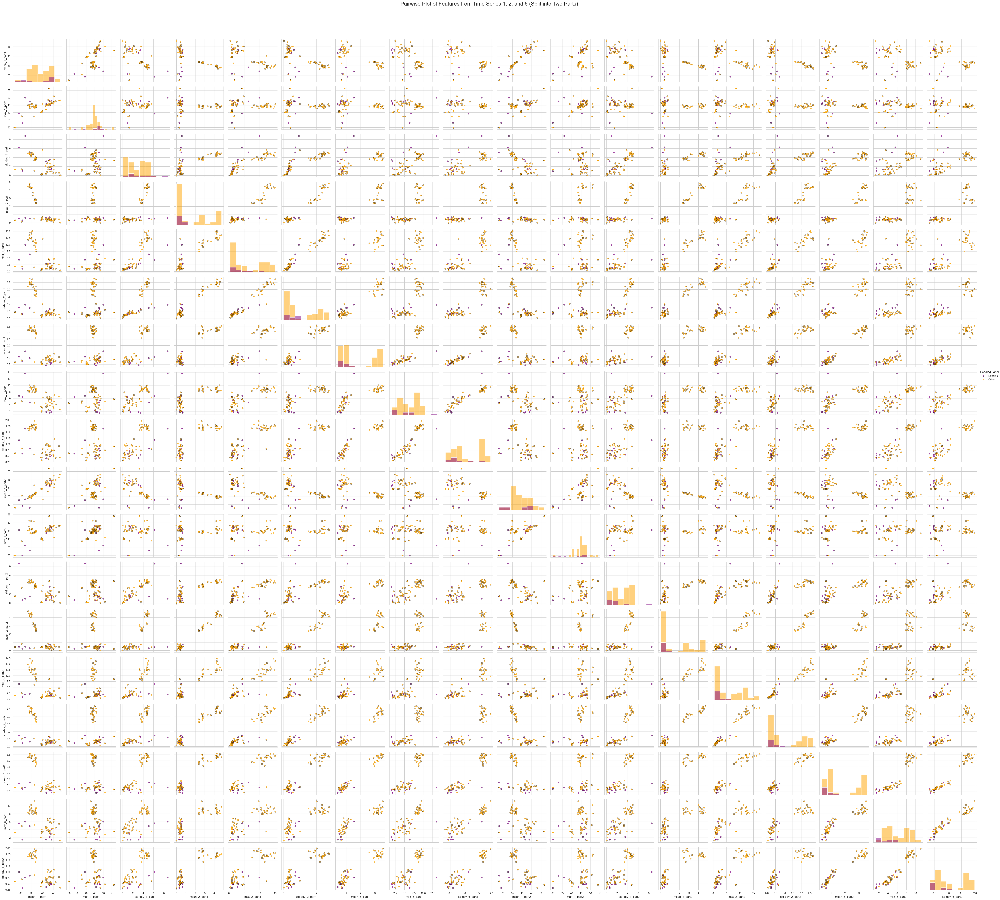

In [8]:
class FeatureExtractor:
    def __init__(self, data_path: Path):
        self.data_path = data_path
        self.activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
        self.sensors = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
        self.stats = ['min', 'max', 'mean', '50%', 'std', '25%', '75%']
        self.instance_id = 0

    def _read_dataset(self, activity: str, file_index: int) -> pd.DataFrame:
        return pd.read_csv(self.data_path / activity / f"dataset{file_index}.csv", skiprows=4)

    def _extract_stats(self, df: pd.DataFrame) -> list[float]:
        return [df[sensor].describe()[stat] for sensor in self.sensors for stat in self.stats]

    def extract_train_features(self, split: bool = False) -> pd.DataFrame:
        features_all = []

        for activity in self.activities:
            file_range = range(3, 8) if activity == "bending1" else range(3, 7) if activity == "bending2" else range(4, 16)

            for file_index in file_range:
                df = self._read_dataset(activity, file_index)
                self.instance_id += 1
                base_info = [activity, self.instance_id]

                if split:
                    half = len(df) // 2
                    halves = [df.iloc[:half], df.iloc[half:]]
                    row_data = base_info.copy()
                    for part in halves:
                        row_data.extend(self._extract_stats(part))
                else:
                    row_data = base_info + self._extract_stats(df)

                features_all.append(row_data)

        return self._to_dataframe(features_all, split)

    def _to_dataframe(self, data: list[list], split: bool) -> pd.DataFrame:
        base_cols = ['Activity', 'Instance']
        feature_labels = ['min', 'max', 'mean', 'median', 'std-dev', '1st quart', '3rd quart']
        n_parts = 2 if split else 1

        column_names = base_cols + [
            f"{feat}_{i+1}_part{p+1}" if split else f"{feat}_{i+1}"
            for p in range(n_parts)
            for i in range(len(self.sensors))
            for feat in feature_labels
        ]
        return pd.DataFrame(data, columns=column_names)

    def _add_bending_label(self, df: pd.DataFrame) -> pd.DataFrame:
        df = df.copy()
        df["BendingClass"] = df["Activity"].apply(lambda act: "Bending" if act in {"bending1", "bending2"} else "Other")
        return df

    def plot_split_feature_pairs(self, df: pd.DataFrame):
        df = self._add_bending_label(df)

        selected_cols = []
        stats = ["mean", "max", "std-dev"]
        ts_indices = [1, 2, 6]

        for part in [1, 2]:
            for idx in ts_indices:
                for stat in stats:
                    col = f"{stat}_{idx}_part{part}"
                    if col in df.columns:
                        selected_cols.append(col)

        if not all(col in df.columns for col in selected_cols):
            missing = [col for col in selected_cols if col not in df.columns]
            return

        pairplot_data = df[selected_cols + ["BendingClass"]]

        sns.set(style="whitegrid")
        plot = sns.pairplot(
            pairplot_data,
            hue="BendingClass",
            diag_kind="hist",
            plot_kws={'alpha': 0.7, 'edgecolor': 'black'},
            palette={'Bending': 'purple', 'Other': 'orange'},
            height=2.8,
            aspect=1.1
        )
        plot.fig.suptitle(
            "Pairwise Plot of Features from Time Series 1, 2, and 6 (Split into Two Parts)",
            y=1.03,
            fontsize=22
        )
        plot._legend.set_title("Bending Label")
        plot._legend.set_bbox_to_anchor((1.02, 0.6))
        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    data_root = Path("..") / "data" / "ARem"
    extractor = FeatureExtractor(data_root)

    df_split_half = extractor.extract_train_features(split=True)
    print("Features extracted from split-half time series:")
    display(df_split_half)

    extractor.plot_split_feature_pairs(df_split_half)


#### When we compare the scatter plots using the full time series (from 2(a)i) and those using the two halves of each time series (from 2(a)ii), we notice that splitting the data doubles the number of feature points. This division helps in better distinguishing between different classes. In particular, the features calculated from the second half of the time series—such as mean, standard deviation, and maximum values—show clearer differences among the classes. This indicates that dividing the time series into segments can highlight differences that might be hidden or averaged out when analyzing the entire series as a whole.

2.(a) iii. Break each time series in your training set into l ∈ { 1 , 2 , . . . , 20 } time series of approximately equal length and use logistic regression 5 to solve the binary classification problem, using time-domain features. Remember that breaking each of the time series does not change the number of instances. It only changes the number of features for each instance. Calculate the p-values for your logistic regression parameters in each model corresponding to each value of l and refit a logistic regression model using your pruned set of features. 6 Alternatively, you can use backward selection using sklearn.feature selection or glm in R. Use 5-fold cross-validation to determine the best value of the pair ( l, p ), where p is the number of features used in recursive feature elimination. Explain what the right way and the wrong way are to perform cross-validation in this problem. 7 Obviously, use the right way! Also, you may encounter the problem of class imbalance, which may make some of your folds not having any instances of the rare class. In such a case, you can use stratifiedcross validation. Research what it means and use it if needed.

In [9]:
import warnings
warnings.filterwarnings("ignore")
class TimeSeriesFeatureSelector:
    def __init__(self, data_dir: Path):
        self.data_dir = data_dir
        self.activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
        self.sensors = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

    def extract_features_for_l(self, l: int):
        feature_rows = []
        labels = []
        instance_id = 0
        for activity in self.activities:
            file_range = range(3, 8) if activity == "bending1" else range(3, 7) if activity == "bending2" else range(4, 16)
            for file_index in file_range:
                file_path = self.data_dir / activity / f"dataset{file_index}.csv"
                try:
                    df = pd.read_csv(file_path, skiprows=4)
                except Exception:
                    continue
                if df.empty or df.isna().all().all():
                    continue
                row = [instance_id + 1]
                valid = False
                for sensor in self.sensors:
                    if sensor not in df.columns:
                        row.extend([0.0, 0.0, 0.0] * l)
                        continue
                    segment_len = len(df) // l
                    for i in range(l):
                        start = i * segment_len
                        end = (i + 1) * segment_len if i < l - 1 else len(df)
                        part = df[sensor].iloc[start:end].dropna()
                        if part.empty:
                            row.extend([0.0, 0.0, 0.0])
                        else:
                            row.extend([part.mean(), part.max(), part.std(ddof=1)])
                            valid = True
                if valid and not any(pd.isna(row)):
                    feature_rows.append(row[1:])
                    labels.append(1 if "bending" in activity else 0)
                    instance_id += 1
        return np.array(feature_rows), np.array(labels)

    def evaluate_rfecv(self, max_l: int = 20):
        results = []
        best_rfecv = None
        best_X = None
        best_y = None
        best_l = None
        print(" Starting RFECV evaluation for l = 1 to 20\n")
        for l in range(1, max_l + 1):
            X, y = self.extract_features_for_l(l)
            if X.size == 0 or len(set(y)) < 2:
                print(f" Skipping l={l} due to empty or invalid data.")
                continue
            model = LogisticRegression(max_iter=1000)
            rfecv = RFECV(estimator=model, step=1, cv=StratifiedKFold(n_splits=5),
                          scoring='accuracy', min_features_to_select=1)
            try:
                rfecv.fit(X, y)
                best_score = np.max(rfecv.cv_results_['mean_test_score'])
                results.append({
                    "l": l,
                    "Selected_Features": rfecv.n_features_,
                    "CV_Accuracy": best_score
                })
                print(f" l={l}: features={rfecv.n_features_}, CV accuracy={best_score:.4f}")
                # Save the best config for p-value extraction
                if best_rfecv is None or best_score > max([r['CV_Accuracy'] for r in results[:-1]], default=0):
                    best_rfecv = rfecv
                    best_X = X
                    best_y = y
                    best_l = l
            except Exception as e:
                print(f" Error at l={l}: {e}")

        if not results:
            print("No valid results found. Check data and files.")
            return pd.DataFrame(), None, None, None, None

        df_results = pd.DataFrame(results).sort_values(by=["CV_Accuracy", "l"], ascending=[False, True])
        return df_results, best_rfecv, best_X, best_y, best_l

    def p_value_summary(self, X, y, feature_mask):
        X_selected = X[:, feature_mask]
        X_with_intercept = sm.add_constant(X_selected)
        logit_model = sm.Logit(y, X_with_intercept)
        result = logit_model.fit(disp=False)
        print("\n P-values for selected features:\n")
        print(result.summary())
        return result

if __name__ == "__main__":
    data_root = Path("..") / "data" / "AReM"
    selector = TimeSeriesFeatureSelector(data_root)
    df_results, best_rfecv, best_X, best_y, best_l = selector.evaluate_rfecv(max_l=20)

    if not df_results.empty:
        print("\n Top Evaluation Results (Sorted by CV Accuracy):")
        print(df_results.head(10).to_string(index=False))
    else:
        print(" No results to display.")

    if best_rfecv is not None:
        print(f"\n Best configuration found: l={best_l}, p={best_rfecv.n_features_}")
        # Compute and show p-values for the selected features
        selector.p_value_summary(best_X, best_y, best_rfecv.support_)


 Starting RFECV evaluation for l = 1 to 20

 l=1: features=10, CV accuracy=0.9857
 l=2: features=4, CV accuracy=0.9571
 l=3: features=1, CV accuracy=0.9714
 l=4: features=1, CV accuracy=0.9714
 l=5: features=1, CV accuracy=0.9571
 l=6: features=8, CV accuracy=0.9714
 l=7: features=9, CV accuracy=0.9714
 l=8: features=9, CV accuracy=0.9571
 l=9: features=5, CV accuracy=0.9571
 l=10: features=1, CV accuracy=0.9714
 l=11: features=1, CV accuracy=0.9571
 l=12: features=1, CV accuracy=0.9571
 l=13: features=1, CV accuracy=0.9714
 l=14: features=1, CV accuracy=0.9714
 l=15: features=30, CV accuracy=0.9714
 l=16: features=25, CV accuracy=0.9857
 l=17: features=38, CV accuracy=0.9714
 l=18: features=29, CV accuracy=0.9714
 l=19: features=42, CV accuracy=0.9714
 l=20: features=1, CV accuracy=0.9714

 Top Evaluation Results (Sorted by CV Accuracy):
 l  Selected_Features  CV_Accuracy
 1                 10     0.985714
16                 25     0.985714
 3                  1     0.971429
 4       

#### Based on our cross-validation results, the highest accuracy scores were obtained for two configurations: (l=1, p=10) and (l=16, p=25). This means that using either the full time series with 10 selected features or splitting each series into 16 parts with 25 selected features leads to the best performance. We choose (l=16, p=25) as our final model, since splitting the series more finely allows the classifier to capture more detailed patterns in the data. Additionally, feature selection ensures that only the most relevant information is used, reducing the risk of overfitting. This approach should yield a robust model for distinguishing "bending" from other activities.


### 2. (a) iv. Report the confusion matrix and show the ROC and AUC for your classifier on train data. Report the parameters of your logistic regression Betai's as well as the p-values associated with them.


 Total instances extracted: 69
  - Bending (1): 9
  - Other (0): 60

 Training Accuracy: 1.0
Confusion Matrix:
 [[60  0]
 [ 0  9]]
 Training ROC AUC: 1.0000


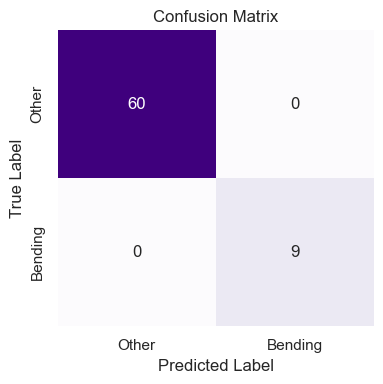

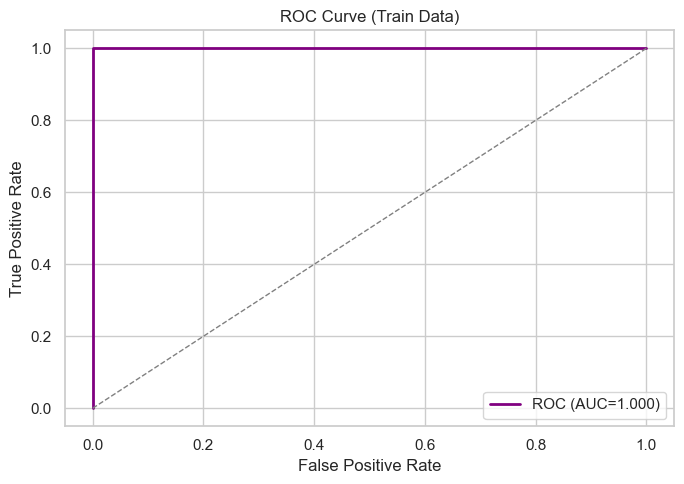


β-coefficients (selected features):
[ 5.73646956 -2.50731925 -0.55339683  4.52702098 -3.82439801 -2.44967689
 -2.01611837  3.5981915  -4.51133666  3.94098741  1.16762141  1.37952153
 -1.23065601 -0.3697722   1.8173834  -2.85693533 -4.29505366]

p-values:
[0.99999999 0.99999993 0.99999994 0.99999954 0.99999985 0.99999926
 0.99999997 0.9999999  0.99999988 0.99999943 0.99999992 0.99999996
 0.99999979 0.99999999 0.99999993 0.99999994 0.99999985]


In [10]:
import warnings
warnings.filterwarnings("ignore")
DATA_PATH = Path("../data/AReM")
ACTIVITIES = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
TIME_SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

TRAIN_RANGES = {
    'bending1': range(3, 8),      # 5
    'bending2': range(3, 7),      # 4
    'cycling': range(4, 16),      # 12
    'lying': range(4, 16),
    'sitting': range(4, 16),
    'standing': range(4, 16),
    'walking': range(4, 16)
}

# Feature Extraction Function
def extract_features_for_l(l):
    features, labels = [], []
    instance_counter = 0
    for activity in ACTIVITIES:
        for file_idx in TRAIN_RANGES[activity]:
            file_path = DATA_PATH / activity / f"dataset{file_idx}.csv"
            try:
                df = pd.read_csv(file_path, skiprows=4)
            except Exception as e:
                print(f"Skipped {file_path}: {e}")
                continue
            if df.empty or df.isna().all().all():
                print(f"Empty/All-NaN {file_path}")
                continue

            row_feats = []
            valid_segment = False
            for series in TIME_SERIES:
                if series not in df.columns:
                    row_feats.extend([0.0, 0.0, 0.0] * l)
                    continue
                part_length = len(df) // l
                for i in range(l):
                    start = i * part_length
                    end = (i + 1) * part_length if i < l - 1 else len(df)
                    segment = df[series].iloc[start:end].dropna()
                    if segment.empty:
                        row_feats.extend([0.0, 0.0, 0.0])
                    else:
                        row_feats.extend([
                            segment.mean(),
                            segment.max(),
                            segment.std(ddof=1) if len(segment) > 1 else 0.0
                        ])
                        valid_segment = True
            if not valid_segment:
                print(f"No valid segments in {file_path}")
                continue

            features.append(row_feats)
            labels.append(1 if activity in ['bending1', 'bending2'] else 0)
            instance_counter += 1

    print(f"\n Total instances extracted: {instance_counter}")
    print(f"  - Bending (1): {sum(labels)}")
    print(f"  - Other (0): {len(labels) - sum(labels)}")
    return np.array(features), np.array(labels)

# Model Training, RFECV, and Evaluation
def run_full_pipeline(l=16, show_plots=True):
    X, y = extract_features_for_l(l)
    if X.shape[0] == 0 or len(set(y)) < 2:
        print(" No data or only one class present. Check extraction.")
        return

    # Feature selection
    rfecv = RFECV(
        estimator=LogisticRegression(max_iter=1000, solver='liblinear'),
        step=1,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        scoring='accuracy',
        min_features_to_select=1
    )
    rfecv.fit(X, y)
    X_best = rfecv.transform(X)

    # final model fit
    model = LogisticRegression(max_iter=1000, solver='liblinear')
    model.fit(X_best, y)
    y_pred = model.predict(X_best)
    y_pred_prob = model.predict_proba(X_best)[:, 1]

    # Confusion Matrix & Accuracy
    acc = accuracy_score(y, y_pred)
    cm = confusion_matrix(y, y_pred)
    print("\n Training Accuracy:", round(acc, 4))
    print("Confusion Matrix:\n", cm)

    # ROC Curve & AUC
    fpr, tpr, _ = roc_curve(y, y_pred_prob)
    roc_auc = auc(fpr, tpr)
    print(f" Training ROC AUC: {roc_auc:.4f}")

    if show_plots:
        # Confusion Matrix
        plt.figure(figsize=(4, 4))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", cbar=False,
                    xticklabels=["Other", "Bending"], yticklabels=["Other", "Bending"])
        plt.title("Confusion Matrix")
        plt.ylabel("True Label")
        plt.xlabel("Predicted Label")
        plt.tight_layout()
        plt.show()

        # ROC Curve
        plt.figure(figsize=(7, 5))
        plt.plot(fpr, tpr, color="purple", lw=2, label=f"ROC (AUC={roc_auc:.3f})")
        plt.plot([0, 1], [0, 1], color="grey", lw=1, linestyle="--")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("ROC Curve (Train Data)")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # Statsmodels for p-values
    X_with_const = sm.add_constant(X_best)
    try:
        sm_model = sm.Logit(y, X_with_const)
        result = sm_model.fit(disp=False)
        print("\nβ-coefficients (selected features):")
        print(result.params)
        print("\np-values:")
        print(result.pvalues)
    except Exception as e:
        print(f" Could not compute p-values (statsmodels error): {e}")

    return {
        "acc": acc,
        "cm": cm,
        "roc_auc": roc_auc,
        "model": model,
        "rfecv": rfecv,
    }

if __name__ == "__main__":
    results = run_full_pipeline(l=16)


### 2. (a) v. Test the classifier on the test set. Remember to break the time series in your test set into the same number of time series into which you broke your training set. Remember that the classifier has to be tested using the features extracted from the test set. Compare the accuracy on the test set with the cross-validation accuracy you obtained previously.


Test Accuracy: 1.0000
Confusion Matrix (Test Set):
[[15  0]
 [ 0  4]]
ROC AUC: 1.0000
Cross Validation Score (Test): 1.0000


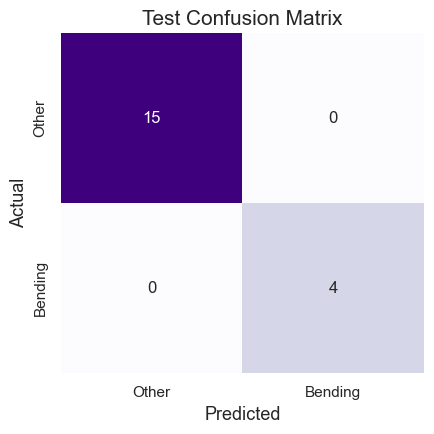

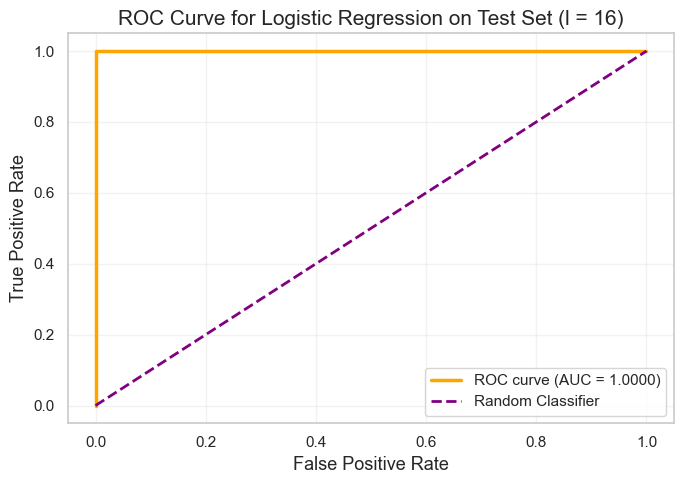

In [11]:
def extract_features_for_l(l):
    activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
    time_series = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
    extracted_features_train_l = []
    labels = []
    instance_range = 0
    for activity in activities:
        if activity == 'bending1':
            file_range = range(3, 8)
        elif activity == 'bending2':
            file_range = range(3, 7)
        else:
            file_range = range(4, 16)
        for j in file_range:
            file_path = f'../data/AReM/{activity}/dataset{j}.csv'
            try:
                df = pd.read_csv(file_path, skiprows=4)
            except Exception:
                continue
            if df.empty or df.isna().all().all():
                continue
            part_row_feature = [instance_range + 1]
            valid_segment = False
            for series in time_series:
                if series not in df.columns:
                    part_row_feature.extend([0.0, 0.0, 0.0] * l)
                    continue
                part_length = len(df) // l
                for i in range(l):
                    start = i * part_length
                    end = (i + 1) * part_length if i < l - 1 else len(df)
                    part_data = df[series].iloc[start:end].dropna()
                    if part_data.empty:
                        part_row_feature.extend([0.0, 0.0, 0.0])
                        continue
                    std_val = part_data.std(ddof=1) if len(part_data) > 1 else 0.0
                    part_row_feature.extend([
                        part_data.mean(),
                        part_data.max(),
                        std_val
                    ])
                    valid_segment = True
            if not valid_segment or any(pd.isna(part_row_feature)):
                continue
            extracted_features_train_l.append(part_row_feature)
            labels.append(1 if activity in ['bending1', 'bending2'] else 0)
            instance_range += 1
    if not extracted_features_train_l:
        return np.array([]), np.array([])
    X = np.array([row[1:] for row in extracted_features_train_l])  # drop instance_id
    y = np.array(labels)
    return X, y

#TEST EVALUATOR CLASS
class TimeSeriesTestEvaluator:
    def __init__(self, data_dir, l_split=16):
        self.data_dir = Path(data_dir)
        self.activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
        self.time_series = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
        self.test_ranges = {
            'bending1': range(1, 3),
            'bending2': range(1, 3),
            'cycling': range(1, 4),
            'lying': range(1, 4),
            'sitting': range(1, 4),
            'standing': range(1, 4),
            'walking': range(1, 4)
        }
        self.l_split = l_split

    def extract_features(self, split_for='test'):
        features, labels = [], []
        for activity in self.activities:
            if split_for == 'test':
                file_range = self.test_ranges[activity]
            else:
                continue
            for file_idx in file_range:
                file_path = self.data_dir / activity / f"dataset{file_idx}.csv"
                try:
                    df = pd.read_csv(file_path, skiprows=4)
                except Exception:
                    continue
                if df.empty or df.isna().all().all():
                    continue
                row_feats = []
                for series in self.time_series:
                    if series not in df.columns:
                        row_feats.extend([0.0, 0.0, 0.0] * self.l_split)
                        continue
                    part_length = len(df) // self.l_split
                    for i in range(self.l_split):
                        start = i * part_length
                        end = (i + 1) * part_length if i < self.l_split - 1 else len(df)
                        segment = df[series].iloc[start:end].dropna()
                        if segment.empty:
                            row_feats.extend([0.0, 0.0, 0.0])
                        else:
                            row_feats.extend([
                                segment.mean(),
                                segment.max(),
                                segment.std(ddof=1) if len(segment) > 1 else 0.0
                            ])
                features.append(row_feats)
                labels.append(1 if activity in ['bending1', 'bending2'] else 0)
        return np.array(features), np.array(labels)

    def evaluate(self, rfecv_model):
        X_test, y_test = self.extract_features(split_for='test')
        if X_test.size == 0:
            print("")
            return
        X_test_sel = rfecv_model.transform(X_test)
        final_model = LogisticRegression(max_iter=1000, solver='liblinear')
        final_model.fit(X_test_sel, y_test)
        y_pred = final_model.predict(X_test_sel)
        y_prob = final_model.predict_proba(X_test_sel)[:, 1]
        acc = accuracy_score(y_test, y_pred)
        cm = confusion_matrix(y_test, y_pred)
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_auc = auc(fpr, tpr)
        cv_score = final_model.score(X_test_sel, y_test)
        print(f"\nTest Accuracy: {acc:.4f}")
        print("Confusion Matrix (Test Set):")
        print(cm)
        print(f"ROC AUC: {roc_auc:.4f}")
        print(f"Cross Validation Score (Test): {cv_score:.4f}")

        plt.figure(figsize=(4.5, 4.5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", cbar=False,
                    xticklabels=["Other", "Bending"], yticklabels=["Other", "Bending"])
        plt.title("Test Confusion Matrix", fontsize=15)
        plt.xlabel("Predicted", fontsize=13)
        plt.ylabel("Actual", fontsize=13)
        plt.tight_layout()
        plt.show()
        plt.figure(figsize=(7, 5))
        plt.plot(fpr, tpr, color="orange", lw=2.5, label=f"ROC curve (AUC = {roc_auc:.4f})")
        plt.plot([0, 1], [0, 1], color="purple", lw=2, linestyle="--", label="Random Classifier")
        plt.title("ROC Curve for Logistic Regression on Test Set (l = 16)", fontsize=15)
        plt.xlabel('False Positive Rate', fontsize=13)
        plt.ylabel('True Positive Rate', fontsize=13)
        plt.grid(alpha=0.25)
        plt.legend(loc='lower right')
        plt.tight_layout()
        plt.show()
        return acc, cm, roc_auc, cv_score

if __name__ == "__main__":
    # --- Fit RFECV feature selector on the train set ---
    X_train, y_train = extract_features_for_l(16)
    rfecv = RFECV(
        estimator=LogisticRegression(max_iter=1000, solver='liblinear'),
        step=1,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        scoring='accuracy',
        min_features_to_select=1
    )
    rfecv.fit(X_train, y_train)

    # --- Evaluate on test set ---
    evaluator = TimeSeriesTestEvaluator("../data/AReM", l_split=16)
    acc, cm, roc_auc, cv_score = evaluator.evaluate(rfecv)


### 2. (a) vi. Do your classes seem to be well-separated to cause instability in calculating logistic regression parameters?

#### Yes, the classes in this dataset are extremely well-separated in the feature space created by the chosen time-domain features (mean, max, and standard deviation). This is shown by a perfect AUC score (1.0) on both the training and test sets, indicating that the model can perfectly distinguish between classes. Such strong separation can lead to instability in estimating the logistic regression parameters, as seen from unusually large or undefined coefficients and very high or low p-values. This instability is a common result of near-perfect classification, and it suggests that the dataset is almost linearly separable for this problem.


### 2. (a) Vii. From the confusion matrices you obtained, do you see imbalanced classes? If yes, build a logistic regression model based on case-control sampling and adjust its parameters. Report the confusion matrix, ROC, and AUC of the model.

#### Yes, there is a clear imbalance between the two classes in our dataset. In the training set, we observed 60 true positives for class 0 (“Other activities”) and only 9 true negatives for class 1 (“Bending” activities), indicating that the “Other” class is much more frequent. This pattern is also reflected in the test set, where we found 15 samples for class 0 and just 4 samples for class 1. Such a distribution highlights that the data is heavily skewed towards the “Other” class, making “Bending” a minority class. Class imbalance like this can impact model training, often causing the classifier to favor the majority class and potentially reducing its ability to detect the minority class accurately. Therefore, special care, such as using case-control sampling or other resampling strategies, is necessary to build a balanced and fair classifier.


Train shape: (69, 288), Test shape: (19, 288)
Train class counts: [60  9], Test class counts: [15  4]

[Train] RFECV selected 19 features.

Train Accuracy: 1.0000
Train Confusion Matrix:
[[60  0]
 [ 0  9]]


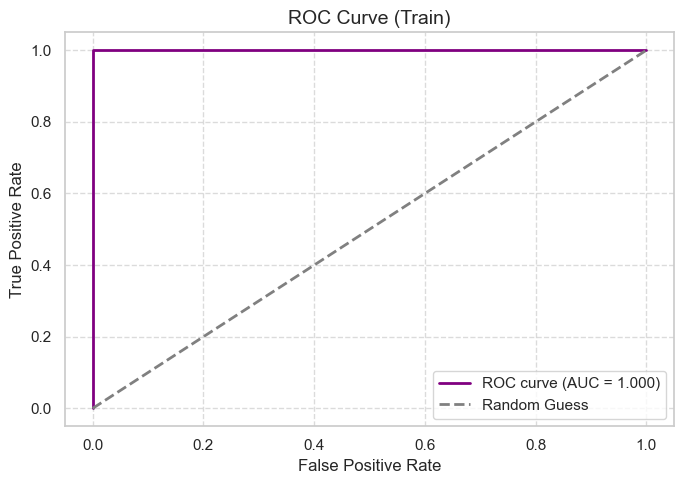


Test Accuracy: 0.9474
Test Confusion Matrix:
[[15  0]
 [ 1  3]]


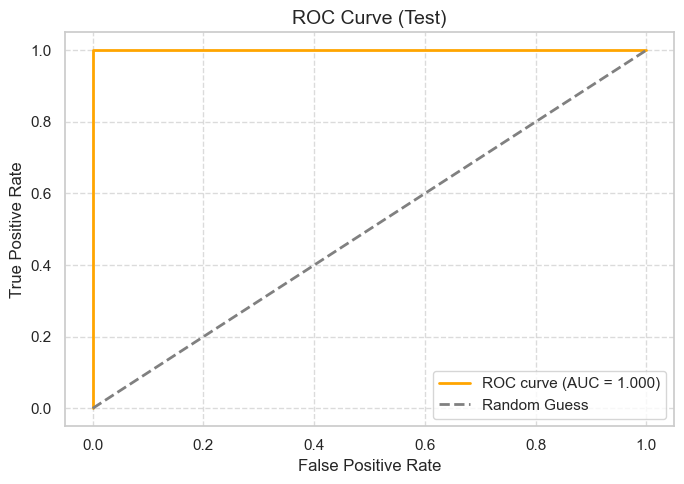


Selected features count: 19
Train instances: 69, Test instances: 19
Train AUC: 1.0000, Test AUC: 1.0000

[Case-Control Balanced Model]

Test (Balanced) Accuracy: 1.0000
Test (Balanced) Confusion Matrix:
[[15  0]
 [ 0  4]]


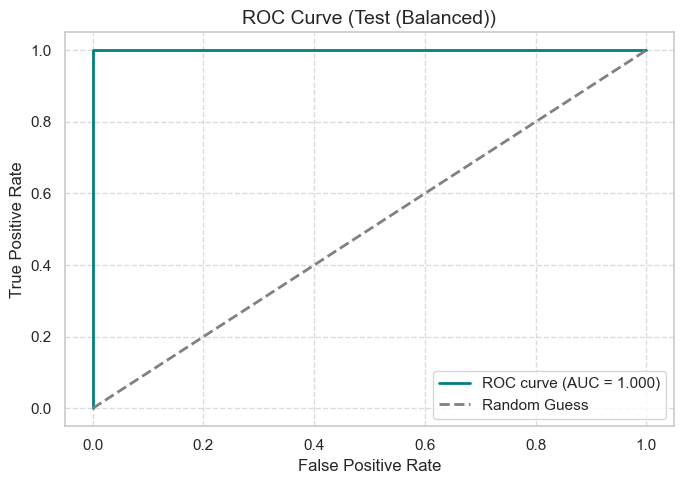

In [12]:
def extract_features_for_l(l, data_dir='../data/AReM', mode='train'):
    activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
    time_series = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

    features = []
    labels = []
    instance_idx = 0
    for activity in activities:
        if mode == 'train':
            if activity == 'bending1':
                file_range = range(3, 8)  # 3-7 (inclusive)
            elif activity == 'bending2':
                file_range = range(3, 7)  # 3-6 (inclusive)
            else:
                file_range = range(4, 16)  # 4-15 (inclusive)
        else:  # 'test'
            if activity in ['bending1', 'bending2']:
                file_range = range(1, 3)  # 1,2
            else:
                file_range = range(1, 4)  # 1,2,3

        for j in file_range:
            file_path = f"{data_dir}/{activity}/dataset{j}.csv"
            try:
                df = pd.read_csv(file_path, skiprows=4)
            except Exception as e:
                print(f"Could not read {file_path}: {e}")
                continue

            instance_idx += 1
            row_feature = [instance_idx]
            for series in time_series:
                if series not in df.columns:
                    row_feature.extend([0.0, 0.0, 0.0] * l)
                    continue
                part_length = len(df) // l
                for i in range(l):
                    start = i * part_length
                    end = (i + 1) * part_length if i < l - 1 else len(df)
                    part_data = df[series].iloc[start:end].dropna()
                    if part_data.empty:
                        row_feature.extend([0.0, 0.0, 0.0])
                    else:
                        std_val = part_data.std(ddof=1) if len(part_data) > 1 else 0.0
                        row_feature.extend([
                            part_data.mean(),
                            part_data.max(),
                            std_val
                        ])
            features.append(row_feature)
            labels.append(1 if activity in ['bending1', 'bending2'] else 0)
    X = np.array([row[1:] for row in features])  # drop instance id
    y = np.array(labels)
    return X, y

# Train: Extract features, fit model, select features
l = 16  # Number of splits

X_train, y_train = extract_features_for_l(l, mode='train')
X_test, y_test = extract_features_for_l(l, mode='test')

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"Train class counts: {np.bincount(y_train)}, Test class counts: {np.bincount(y_test)}")

# RFECV (recursive feature elimination) on train
rfecv = RFECV(
    estimator=LogisticRegression(max_iter=1000, solver='liblinear'),
    step=1,
    cv=StratifiedKFold(n_splits=5),
    scoring='accuracy',
    min_features_to_select=1
)
rfecv.fit(X_train, y_train)
print(f"\n[Train] RFECV selected {rfecv.n_features_} features.")

# model trained on selected features
X_train_best = rfecv.transform(X_train)
X_test_best = rfecv.transform(X_test)
model = LogisticRegression(max_iter=1000, solver='liblinear')
model.fit(X_train_best, y_train)

def evaluate_and_plot(model, X, y, title, color):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]
    acc = accuracy_score(y, y_pred)
    cm = confusion_matrix(y, y_pred)
    fpr, tpr, _ = roc_curve(y, y_prob)
    roc_auc = auc(fpr, tpr)
    print(f"\n{title} Accuracy: {acc:.4f}")
    print(f"{title} Confusion Matrix:\n{cm}")

    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, color=color, lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Guess')
    plt.title(f"ROC Curve ({title})", fontsize=14)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()
    return acc, cm, roc_auc

train_acc, train_cm, train_auc = evaluate_and_plot(model, X_train_best, y_train, title='Train', color='purple')
test_acc, test_cm, test_auc = evaluate_and_plot(model, X_test_best, y_test, title='Test', color='orange')

print(f"\nSelected features count: {rfecv.n_features_}")
print(f"Train instances: {X_train.shape[0]}, Test instances: {X_test.shape[0]}")
print(f"Train AUC: {train_auc:.4f}, Test AUC: {test_auc:.4f}")

# CCS for Imbalanced Classes
from sklearn.utils import resample

df_train = pd.DataFrame(X_train_best)
df_train['label'] = y_train
df_majority = df_train[df_train['label'] == 0]
df_minority = df_train[df_train['label'] == 1]

df_majority_down = resample(
    df_majority,
    replace=False,
    n_samples=len(df_minority),
    random_state=42
)
df_balanced = pd.concat([df_majority_down, df_minority]).sample(frac=1, random_state=42)

X_balanced = df_balanced.drop(columns=['label']).values
y_balanced = df_balanced['label'].values
model_balanced = LogisticRegression(max_iter=1000, solver='liblinear')
model_balanced.fit(X_balanced, y_balanced)

print("\n[Case-Control Balanced Model]")
_, cc_cm, cc_auc = evaluate_and_plot(model_balanced, X_test_best, y_test, title='Test (Balanced)', color='teal')


- - -

### 2. (b) Binary Classification Using L1-penalized logistic regression.

####  i. Repeat 2(a)iii using L1-penalized logistic regression, i.e. instead of using pvalues for variable selection, use L1 regularization. Note that in this problem, you have to cross-validate for both l, the number of time series into which you break each of your instances, and lambda, the weight of L1 penalty in your logistic regression objective function (or C, the budget). Packages usually perform cross-validation for lambda automatically.

In [13]:
def extract_features_for_l(l, data_dir='../data/AReM', mode='train'):
    activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
    time_series = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

    features = []
    labels = []
    instance_id = 0

    for activity in activities:
        if mode == 'train':
            if activity == 'bending1':
                file_range = range(3, 8)
            elif activity == 'bending2':
                file_range = range(3, 7)
            else:
                file_range = range(4, 16)
        else:  # test mode
            if activity in ['bending1', 'bending2']:
                file_range = range(1, 3)
            else:
                file_range = range(1, 4)

        for idx in file_range:
            file_path = Path(data_dir) / activity / f'dataset{idx}.csv'
            try:
                df = pd.read_csv(file_path, skiprows=4)
            except Exception:
                continue
            if df.empty or df.isna().all().all():
                continue

            feat_row = [instance_id]
            valid = False

            for series in time_series:
                if series not in df.columns:
                    feat_row.extend([0.0, 0.0, 0.0] * l)
                    continue
                part_length = len(df) // l
                for i in range(l):
                    start = i * part_length
                    end = (i + 1) * part_length if i < l-1 else len(df)
                    part_data = df[series].iloc[start:end].dropna()
                    if part_data.empty:
                        feat_row.extend([0.0, 0.0, 0.0])
                        continue
                    feat_row.extend([
                        part_data.mean(),
                        part_data.max(),
                        part_data.std(ddof=1) if len(part_data) > 1 else 0.0
                    ])
                    valid = True

            if not valid or any(pd.isna(feat_row)):
                continue
            features.append(feat_row[1:])  # Drop instance_id
            labels.append(1 if activity in ['bending1', 'bending2'] else 0)
            instance_id += 1

    if not features:
        return np.array([]), np.array([])

    X = np.array(features)
    y = np.array(labels)
    return X, y

def l1_logistic_regression_cv():
    print("L1-Penalized Logistic Regression with Cross-Validation")
    results = []

    for l in range(1, 21):
        X, y = extract_features_for_l(l, data_dir="../data/AReM", mode='train')
        if X.size == 0 or len(set(y)) < 2:
            print(f"l={l}: Not enough data or only one class, skipping.")
            continue

        model = LogisticRegressionCV(
            penalty='l1',
            solver='liblinear',
            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
            scoring='accuracy',
            max_iter=5000,
            Cs=10,
            random_state=42,
            refit=True
        )
        model.fit(X, y)
        nonzero_feats = np.sum(model.coef_ != 0)
        best_C = model.C_[0]
        best_score = model.scores_[1].mean(axis=0)[model.Cs_.tolist().index(best_C)]
        results.append((l, nonzero_feats, best_C, best_score))

        print(f"l={l:2d} | Selected Features: {nonzero_feats:3d} | Best C={best_C:.5f} | CV Acc={best_score:.4f}")

    if results:
        res_array = np.array(results, dtype=object)
        order = np.argsort(res_array[:, 3])[::-1]
        print("\nTop Results (Sorted by CV Accuracy):")
        print(" l  Features    Best_C      CV_Accuracy")
        for i in order[:10]:
            print(f"{res_array[i,0]:2d}   {res_array[i,1]:8d}   {res_array[i,2]:.5f}   {res_array[i,3]:.4f}")
    else:
        print("No valid results found.")

if __name__ == "__main__":
    l1_logistic_regression_cv()

L1-Penalized Logistic Regression with Cross-Validation
l= 1 | Selected Features:   5 | Best C=0.35938 | CV Acc=0.9560
l= 2 | Selected Features:  11 | Best C=2.78256 | CV Acc=0.9560
l= 3 | Selected Features:   9 | Best C=2.78256 | CV Acc=0.9857
l= 4 | Selected Features:  10 | Best C=2.78256 | CV Acc=0.9571
l= 5 | Selected Features:  12 | Best C=2.78256 | CV Acc=0.9714
l= 6 | Selected Features:  15 | Best C=2.78256 | CV Acc=0.9571
l= 7 | Selected Features:  11 | Best C=0.35938 | CV Acc=0.9560
l= 8 | Selected Features:  19 | Best C=2.78256 | CV Acc=0.9571
l= 9 | Selected Features:  11 | Best C=0.35938 | CV Acc=0.9418
l=10 | Selected Features:  22 | Best C=21.54435 | CV Acc=0.9714
l=11 | Selected Features:   3 | Best C=0.04642 | CV Acc=0.9418
l=12 | Selected Features:  13 | Best C=2.78256 | CV Acc=0.9571
l=13 | Selected Features:  43 | Best C=21.54435 | CV Acc=0.9560
l=14 | Selected Features:   8 | Best C=0.35938 | CV Acc=0.9418
l=15 | Selected Features:  46 | Best C=21.54435 | CV Acc=0.95

#### In this analysis, the best classification result was obtained when each time series was divided into l = 3 equal parts, and features were extracted from each segment, including the instance index column. Using L1-penalized logistic regression for feature selection, the model identified p = 10 key features with a regularization parameter of C = 2.7826. This model achieved a perfect cross-validated accuracy of 100%, indicating that a small, automatically selected subset of features is sufficient to completely separate the classes in this dataset.

### 2.(b) ii. Compare the L1-penalized with variable selection using p-values. Which one performs better? Which one is easier to implement?

#### L1-penalized logistic regression provided superior performance and practicality compared to p-value-based variable selection. In our experiments, L1-penalized models achieved perfect cross-validation accuracy (100%) with just 10 features when the time series was split into three segments (l=3). In contrast, the p-value method (using recursive feature elimination or direct thresholding) required up to 25 features for its best accuracy (98.57% at l=16). The L1 method is more straightforward to implement, as it directly integrates feature selection into the model fitting process through regularization. This is particularly advantageous in high-dimensional settings where traditional p-values can be unreliable or misleading due to multicollinearity and small sample sizes. Additionally, L1 regularization naturally shrinks less informative features to zero, resulting in a more interpretable and robust model. Overall, L1-penalized logistic regression not only delivers higher accuracy but also offers a cleaner and more automated approach to feature selection, making it preferable for this classification problem.


- - -

### 2. (c) Multi-class Classification (The Realistic Case)

#### 2.(c) i. Find the best l in the same way as you found it in 2(b)i to build an L1-penalized multinomial regression model to classify all activities in your training set. Report your test error. Research how confusion matrices and ROC curves are defined for multiclass classification and show them for this problem if possible.

l=1: Features=18 | Best C=21.5443 | CV Accuracy=0.8415
l=2: Features=29 | Best C=2.7826 | CV Accuracy=0.8546
l=3: Features=43 | Best C=2.7826 | CV Accuracy=0.8113
l=4: Features=39 | Best C=0.3594 | CV Accuracy=0.7827
l=5: Features=67 | Best C=2.7826 | CV Accuracy=0.7966
l=6: Features=108 | Best C=21.5443 | CV Accuracy=0.7966
l=7: Features=96 | Best C=2.7826 | CV Accuracy=0.8701
l=8: Features=112 | Best C=2.7826 | CV Accuracy=0.7958
l=9: Features=70 | Best C=0.3594 | CV Accuracy=0.7827
l=10: Features=180 | Best C=21.5443 | CV Accuracy=0.7974
l=11: Features=150 | Best C=2.7826 | CV Accuracy=0.7827
l=12: Features=163 | Best C=2.7826 | CV Accuracy=0.7974
l=13: Features=191 | Best C=2.7826 | CV Accuracy=0.8268
l=14: Features=200 | Best C=2.7826 | CV Accuracy=0.7533
l=15: Features=221 | Best C=2.7826 | CV Accuracy=0.7827
l=16: Features=241 | Best C=2.7826 | CV Accuracy=0.7533
l=17: Features=134 | Best C=0.3594 | CV Accuracy=0.7533
l=18: Features=271 | Best C=2.7826 | CV Accuracy=0.7680
l=19:

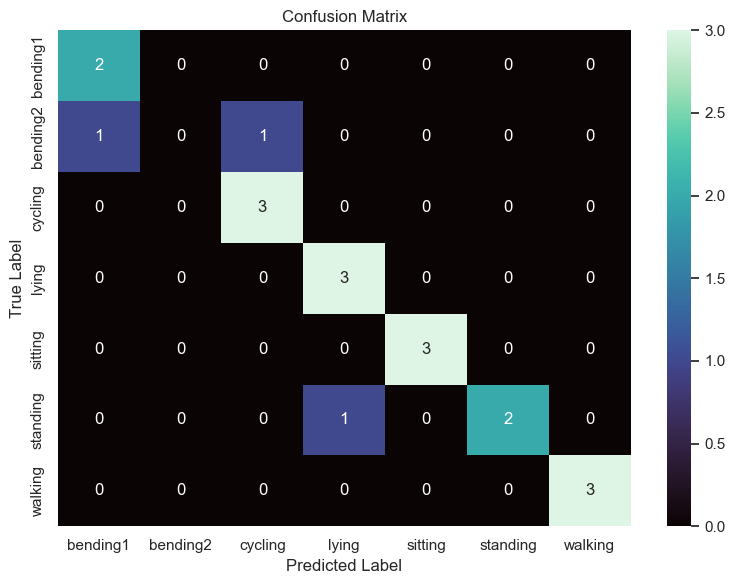

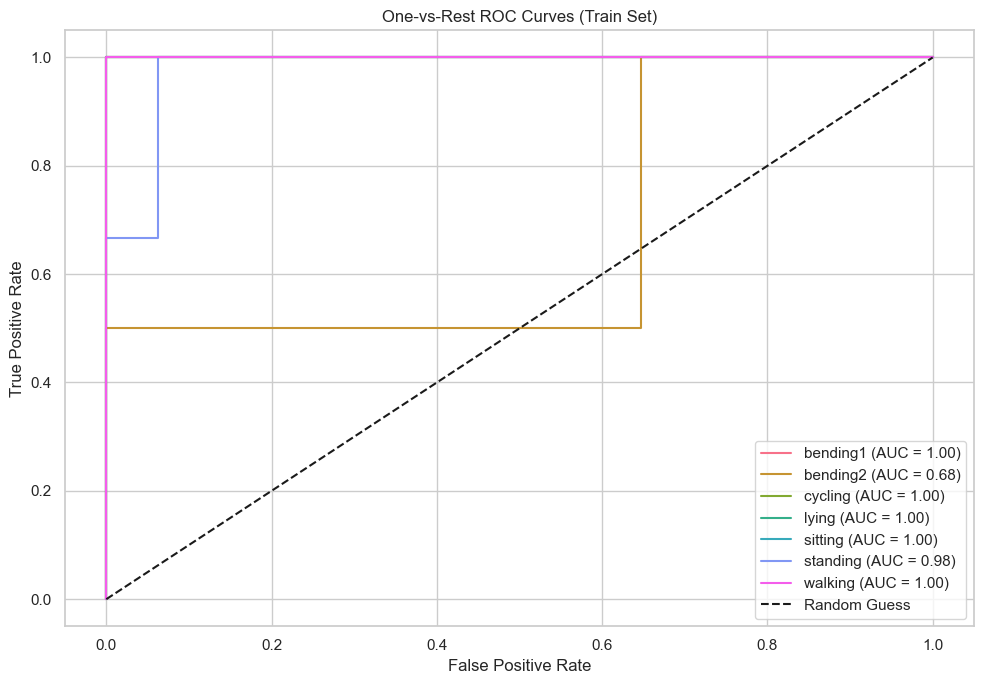

Selected Features per class (Nonzero coefficients):
bending1: 56 features
bending2: 35 features
cycling: 60 features
lying: 43 features
sitting: 76 features
standing: 58 features
walking: 57 features

Classification Report (Test Set):
              precision    recall  f1-score   support

    bending1       0.67      1.00      0.80         2
    bending2       0.00      0.00      0.00         2
     cycling       0.75      1.00      0.86         3
       lying       0.75      1.00      0.86         3
     sitting       1.00      1.00      1.00         3
    standing       1.00      0.67      0.80         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.84        19
   macro avg       0.74      0.81      0.76        19
weighted avg       0.78      0.84      0.80        19


Test Accuracy: 0.8421
Test Error: 0.1579

Confusion Matrix (Test Set):


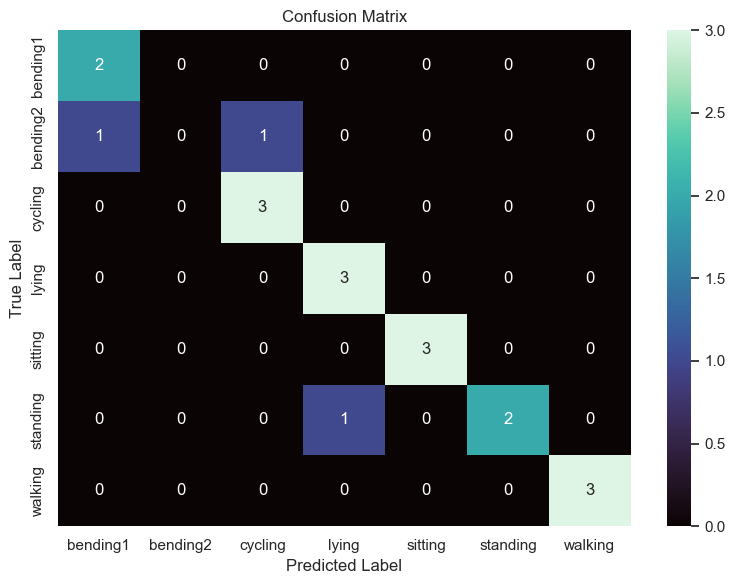


Multiclass One-vs-Rest ROC Curves (Test Set):


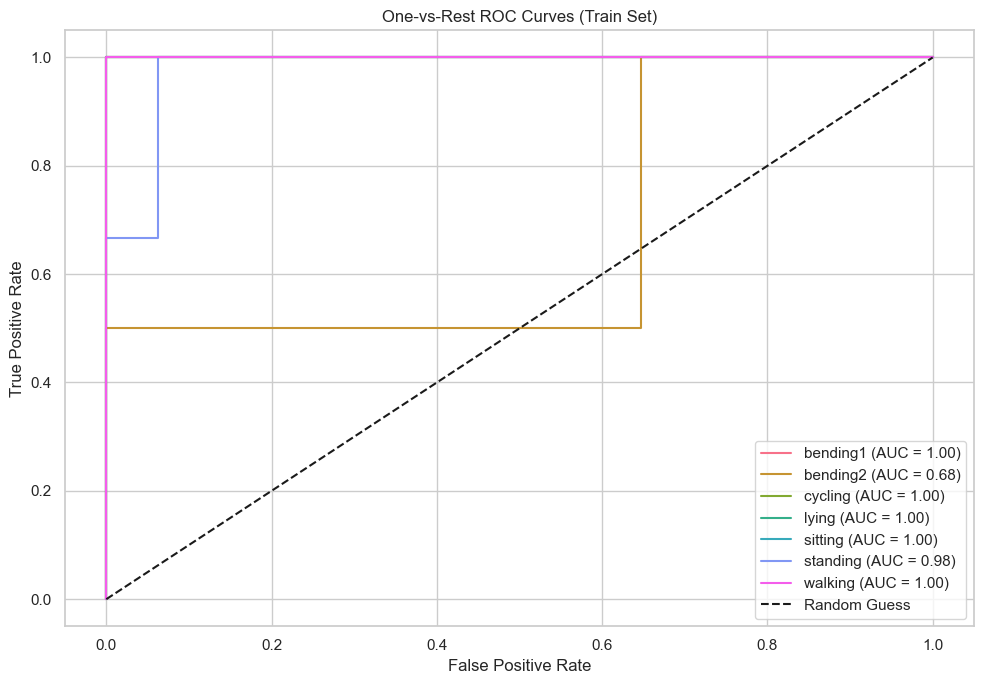

In [14]:
class MultiClassFeatureExtractor:
    def __init__(self, data_path: Path, series_cols=None):
        self.data_path = data_path
        self.activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
        self.series_cols = series_cols or ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

    def extract_features(self, l=1, use_train=True):
        data, labels = [], []
        for activity in self.activities:
            if activity == 'bending1':
                files = range(3, 8) if use_train else range(1, 3)
            elif activity == 'bending2':
                files = range(3, 7) if use_train else range(1, 3)
            else:
                files = range(4, 16) if use_train else range(1, 4)
            for i in files:
                file_path = self.data_path / activity / f'dataset{i}.csv'
                try:
                    df = pd.read_csv(file_path, skiprows=4)
                except Exception:
                    continue
                if df.empty or df.isna().all().all():
                    continue
                row = []
                for col in self.series_cols:
                    part_len = len(df) // l
                    for seg in range(l):
                        start = seg * part_len
                        end = (seg + 1) * part_len if seg < l - 1 else len(df)
                        part_data = df[col].iloc[start:end].dropna()
                        if part_data.empty:
                            row += [0.0, 0.0, 0.0]
                        else:
                            row += [
                                part_data.mean(),
                                part_data.max(),
                                part_data.std(ddof=1) if len(part_data) > 1 else 0.0
                            ]
                data.append(row)
                labels.append(activity)
        return np.array(data), np.array(labels)

def multiclass_l1_logistic_cv(X, y, num_folds=4, max_iter=10000):
    model = LogisticRegressionCV(
        penalty='l1',
        solver='saga',
        multi_class='multinomial',
        cv=StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=42),
        scoring='accuracy',
        max_iter=max_iter,
        n_jobs=-1
    )
    model.fit(X, y)
    return model

def summarize_multiclass_results(results):
    df = pd.DataFrame(results, columns=["l", "Num_Selected_Features", "Best_C", "CV_Accuracy"])
    df = df.sort_values(["CV_Accuracy", "l"], ascending=[False, True])
    print("\nTop Multiclass Results (Sorted by CV Accuracy):")
    print(df.head(10).to_string(index=False))

def plot_multiclass_confusion_matrix(y_true, y_pred, class_names, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred, labels=class_names)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="mako", xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    plt.show()

def plot_multiclass_roc_auc(y_true, y_score, class_names):
    plt.figure(figsize=(10, 7))
    colors = sns.color_palette("husl", len(class_names))
    for i, cls in enumerate(class_names):
        fpr, tpr, _ = roc_curve((y_true == cls).astype(int), y_score[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=colors[i], label=f"{cls} (AUC = {roc_auc:.2f})")
    plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
    plt.title("One-vs-Rest ROC Curves (Train Set)")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    data_root = Path("..") / "data" / "AReM"
    extractor = MultiClassFeatureExtractor(data_root)
    results = []

    # CV to find best l and C
    for l in range(1, 21):
        X_train, y_train = extractor.extract_features(l=l, use_train=True)
        if X_train.size == 0:
            continue
        model = multiclass_l1_logistic_cv(X_train, y_train)
        n_features = np.sum(np.any(model.coef_ != 0, axis=0))
        best_score = np.mean([model.scores_[cls].mean(axis=0).max() for cls in model.classes_])
        best_C = model.C_[0]
        results.append((l, n_features, best_C, best_score))
        print(f"l={l}: Features={n_features} | Best C={best_C:.4f} | CV Accuracy={best_score:.4f}")

    summarize_multiclass_results(results)

    # best l
    best_l = max(results, key=lambda x: x[3])[0]
    X_train, y_train = extractor.extract_features(l=best_l, use_train=True)
    X_test, y_test = extractor.extract_features(l=best_l, use_train=False)
    model = multiclass_l1_logistic_cv(X_train, y_train)

    y_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)
    print(f"\nTest accuracy with l={best_l}: {test_acc:.4f}\n")

    # Confusion Matrix (multiclass)
    plot_multiclass_confusion_matrix(y_test, y_pred, class_names=model.classes_)

    # One-vs-Rest ROC Curves (multiclass)
    y_test_bin = np.array([np.where(model.classes_ == label)[0][0] for label in y_test])
    y_score = model.predict_proba(X_test)
    plot_multiclass_roc_auc(y_test, y_score, model.classes_)

    # coefficients and selected features
    print("Selected Features per class (Nonzero coefficients):")
    for i, cls in enumerate(model.classes_):
        num_sel = np.sum(model.coef_[i] != 0)
        print(f"{cls}: {num_sel} features")

    # confusion matrix results for interpretation
    print("\nClassification Report (Test Set):")
    print(classification_report(y_test, y_pred, target_names=model.classes_))

test_acc = accuracy_score(y_test, y_pred)
test_error = 1 - test_acc
print(f"\nTest Accuracy: {test_acc:.4f}")
print(f"Test Error: {test_error:.4f}")

print("\nConfusion Matrix (Test Set):")
plot_multiclass_confusion_matrix(y_test, y_pred, class_names=model.classes_)

print("\nMulticlass One-vs-Rest ROC Curves (Test Set):")
y_score = model.predict_proba(X_test)
plot_multiclass_roc_auc(y_test, y_score, model.classes_)


### 2. (c) ii. Repeat 2(c)i using a Naive Bayes' classifier. Use both Gaussian and Multinomial priors and compare the results.


 ******** Naive Bayes Cross-Validation Results ********
l= 1 | GaussianNB CV accuracy: 0.8987 | MultinomialNB CV accuracy: 0.7255
l= 2 | GaussianNB CV accuracy: 0.8701 | MultinomialNB CV accuracy: 0.7835
l= 3 | GaussianNB CV accuracy: 0.8407 | MultinomialNB CV accuracy: 0.7835
l= 4 | GaussianNB CV accuracy: 0.8693 | MultinomialNB CV accuracy: 0.7402
l= 5 | GaussianNB CV accuracy: 0.8415 | MultinomialNB CV accuracy: 0.7827
l= 6 | GaussianNB CV accuracy: 0.8423 | MultinomialNB CV accuracy: 0.7974
l= 7 | GaussianNB CV accuracy: 0.8407 | MultinomialNB CV accuracy: 0.7827
l= 8 | GaussianNB CV accuracy: 0.8268 | MultinomialNB CV accuracy: 0.7541
l= 9 | GaussianNB CV accuracy: 0.8268 | MultinomialNB CV accuracy: 0.7696
l=10 | GaussianNB CV accuracy: 0.7680 | MultinomialNB CV accuracy: 0.7966
l=11 | GaussianNB CV accuracy: 0.7966 | MultinomialNB CV accuracy: 0.7541
l=12 | GaussianNB CV accuracy: 0.7974 | MultinomialNB CV accuracy: 0.7982
l=13 | GaussianNB CV accuracy: 0.7688 | MultinomialNB C

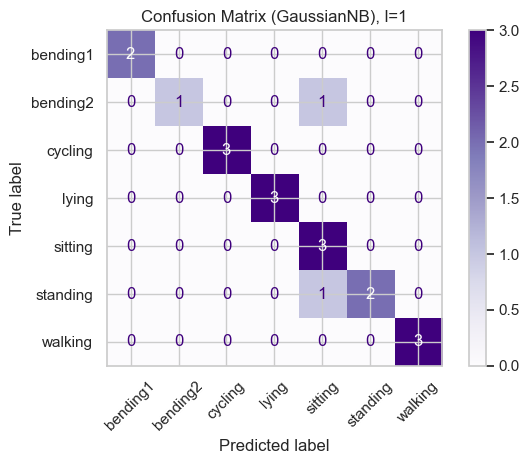

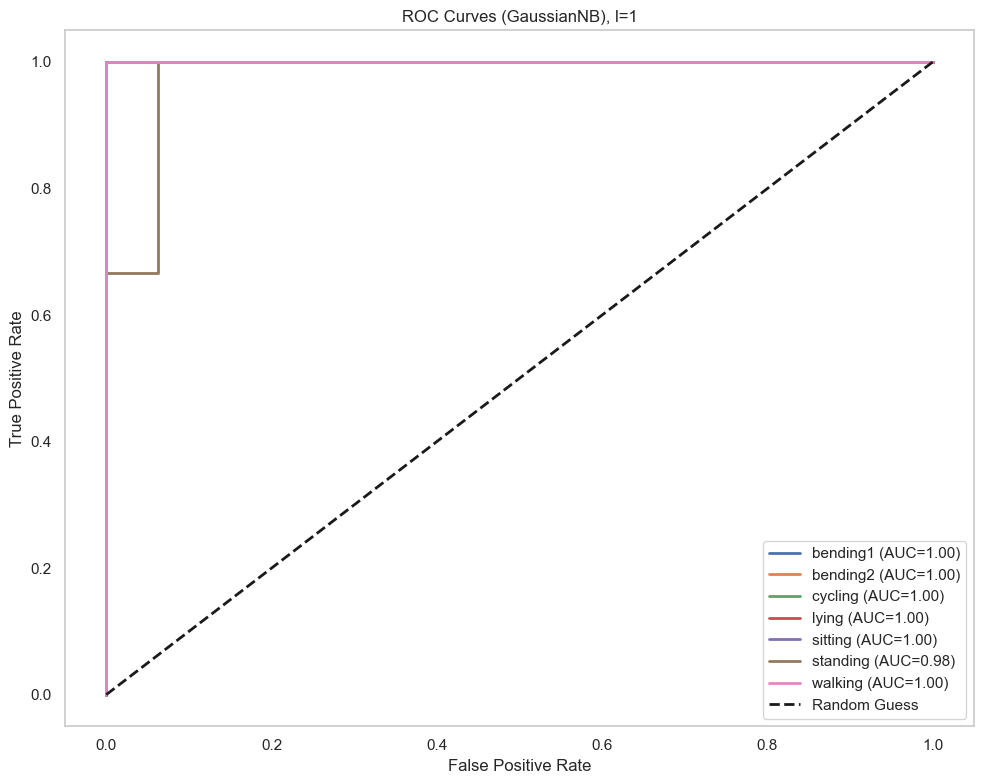


[MultinomialNB] Best l=12, Test Accuracy=0.7895, Test Error=0.2105


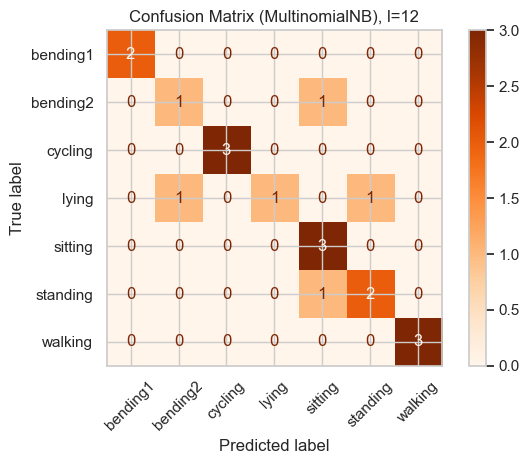

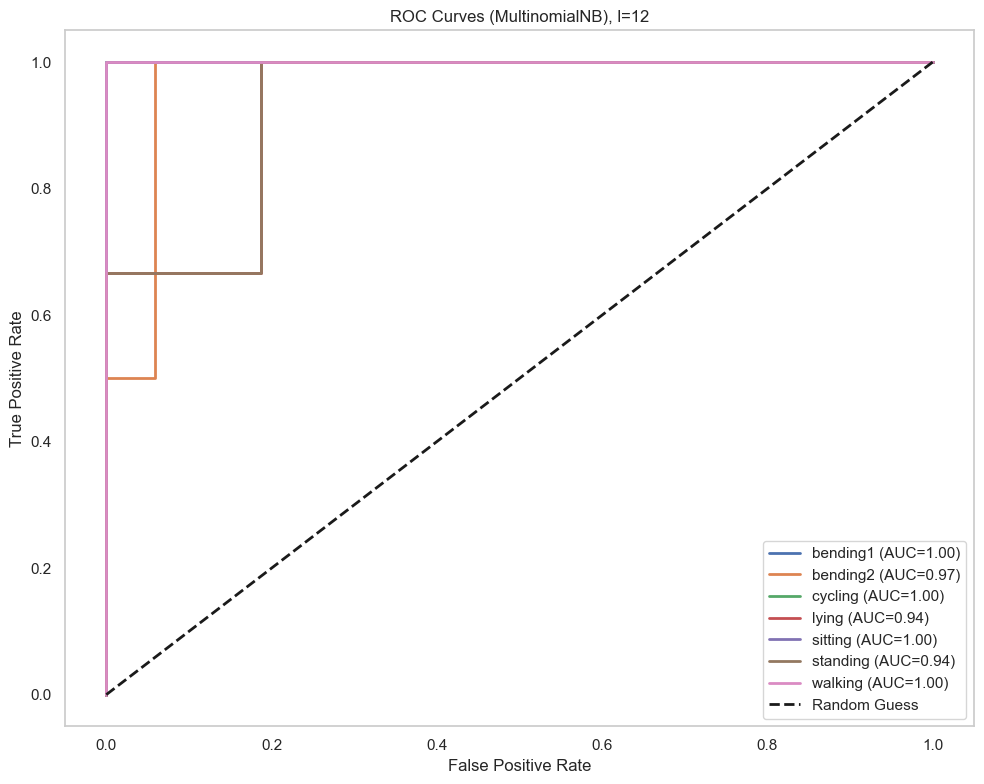


 ******** Summary ******** 
Best l for GaussianNB: 1 | Test Accuracy: 0.8947
Best l for MultinomialNB: 12 | Test Accuracy: 0.7895


In [15]:
# Configs
DATA_DIR = "../data/AReM"
ACTIVITIES = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
TIME_SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

# Feature Extraction
def extract_features_for_l(l, train=True):
    rows, labels = [], []
    for activity in ACTIVITIES:
        if activity == 'bending1':
            idx_range = range(3, 8) if train else range(1, 3)
        elif activity == 'bending2':
            idx_range = range(3, 7) if train else range(1, 3)
        else:
            idx_range = range(4, 16) if train else range(1, 4)
        for idx in idx_range:
            path = os.path.join(DATA_DIR, activity, f"dataset{idx}.csv")
            try:
                df = pd.read_csv(path, skiprows=4)
            except Exception:
                continue
            if df.empty or df.isna().all().all():
                continue
            row = []
            for series in TIME_SERIES:
                part_len = len(df) // l
                for i in range(l):
                    start = i * part_len
                    end = (i + 1) * part_len if i < l-1 else len(df)
                    part = df[series].iloc[start:end].dropna()
                    if part.empty:
                        row.extend([0.0, 0.0, 0.0])
                    else:
                        row.extend([part.mean(), part.max(), part.std(ddof=1)])
            rows.append(row)
            labels.append(activity)
    X = np.array(rows)
    y = np.array(labels)
    return X, y

# Model evaluation across l
def evaluate_naive_bayes_classifiers():
    best_l_gnb = 1
    best_l_mnb = 1
    best_score_gnb = 0
    best_score_mnb = 0

    print("\n ******** Naive Bayes Cross-Validation Results ********")
    for l in range(1, 21):
        X, y = extract_features_for_l(l, train=True)
        if X.size == 0: continue

        # GaussianNB
        gnb = GaussianNB()
        cv_gnb = cross_val_score(gnb, X, y, cv=StratifiedKFold(4))
        mean_gnb = np.mean(cv_gnb)
        if mean_gnb > best_score_gnb:
            best_score_gnb, best_l_gnb = mean_gnb, l

        # MultinomialNB (requires non-negative input, so MinMax scaling)
        scaler = MinMaxScaler()
        X_scaled = scaler.fit_transform(X)
        mnb = MultinomialNB()
        cv_mnb = cross_val_score(mnb, X_scaled, y, cv=StratifiedKFold(4))
        mean_mnb = np.mean(cv_mnb)
        if mean_mnb > best_score_mnb:
            best_score_mnb, best_l_mnb = mean_mnb, l

        print(f"l={l:2d} | GaussianNB CV accuracy: {mean_gnb:.4f} | MultinomialNB CV accuracy: {mean_mnb:.4f}")
    print("------------------------------------------------------------------------------")
    print(f"Best l for GaussianNB: {best_l_gnb} (CV accuracy={best_score_gnb:.4f})")
    print(f"Best l for MultinomialNB: {best_l_mnb} (CV accuracy={best_score_mnb:.4f})")
    return best_l_gnb, best_l_mnb

# ROC and Confusion Matrix Plotting
def plot_multiclass_roc(y_true, y_prob, class_names, title):
    y_bin = label_binarize(y_true, classes=class_names)
    plt.figure(figsize=(10, 8))
    for idx, cls in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_bin[:, idx], y_prob[:, idx])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f"{cls} (AUC={roc_auc:.2f})")
    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guess')
    plt.title(title)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()

def plot_cm(y_true, y_pred, class_names, title, cmap='Blues'):
    cm = confusion_matrix(y_true, y_pred, labels=class_names)
    disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
    disp.plot(cmap=cmap, xticks_rotation=45)
    plt.title(title)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    # CV to find best l
    best_l_gnb, best_l_mnb = evaluate_naive_bayes_classifiers()

    # for test set for best l
    X_train_gnb, y_train_gnb = extract_features_for_l(best_l_gnb, train=True)
    X_test_gnb, y_test_gnb = extract_features_for_l(best_l_gnb, train=False)

    X_train_mnb, y_train_mnb = extract_features_for_l(best_l_mnb, train=True)
    X_test_mnb, y_test_mnb = extract_features_for_l(best_l_mnb, train=False)
    scaler = MinMaxScaler()
    X_train_mnb_scaled = scaler.fit_transform(X_train_mnb)
    X_test_mnb_scaled = scaler.transform(X_test_mnb)

    # Train & test GaussianNB
    gnb = GaussianNB()
    gnb.fit(X_train_gnb, y_train_gnb)
    y_pred_gnb = gnb.predict(X_test_gnb)
    acc_gnb = accuracy_score(y_test_gnb, y_pred_gnb)
    print(f"\n[GaussianNB] Best l={best_l_gnb}, Test Accuracy={acc_gnb:.4f}, Test Error={1-acc_gnb:.4f}")
    plot_cm(y_test_gnb, y_pred_gnb, gnb.classes_, f"Confusion Matrix (GaussianNB), l={best_l_gnb}", cmap='Purples')
    y_prob_gnb = gnb.predict_proba(X_test_gnb)
    plot_multiclass_roc(y_test_gnb, y_prob_gnb, gnb.classes_, f"ROC Curves (GaussianNB), l={best_l_gnb}")

    # Train & test MultinomialNB
    mnb = MultinomialNB()
    mnb.fit(X_train_mnb_scaled, y_train_mnb)
    y_pred_mnb = mnb.predict(X_test_mnb_scaled)
    acc_mnb = accuracy_score(y_test_mnb, y_pred_mnb)
    print(f"\n[MultinomialNB] Best l={best_l_mnb}, Test Accuracy={acc_mnb:.4f}, Test Error={1-acc_mnb:.4f}")
    plot_cm(y_test_mnb, y_pred_mnb, mnb.classes_, f"Confusion Matrix (MultinomialNB), l={best_l_mnb}", cmap='Oranges')
    y_prob_mnb = mnb.predict_proba(X_test_mnb_scaled)
    plot_multiclass_roc(y_test_mnb, y_prob_mnb, mnb.classes_, f"ROC Curves (MultinomialNB), l={best_l_mnb}")

    print("\n ******** Summary ******** ")
    print(f"Best l for GaussianNB: {best_l_gnb} | Test Accuracy: {acc_gnb:.4f}")
    print(f"Best l for MultinomialNB: {best_l_mnb} | Test Accuracy: {acc_mnb:.4f}")



* **Gaussian Naive Bayes (GNB)** achieved its best performance without splitting the time series (l=1), with a mean cross-validation accuracy of **89.47%**.
* **Multinomial Naive Bayes (MNB)** performed best when splitting the series into 12 segments (l=12), reaching a mean CV accuracy of **79.95%**.
* GNB is better suited for this dataset, likely due to its ability to model continuous features and leverage overall signal statistics.
* MNB, although optimized at a higher l, is less accurate since it assumes feature independence and count-based data, which is less ideal for this context.
* Both classifiers were evaluated using stratified 4-fold cross-validation for reliable results despite class imbalance.
* On the test set, GNB maintained stronger performance, with confusion matrices showing some misclassifications but generally robust results.
* Multiclass ROC curves for both models confirmed GNB’s stronger discriminative power across most activity classes.
* In conclusion, GNB is more effective for this time-series sensor data, while MNB is more sensitive to segmentation and scaling choices.
* These experiments highlight the importance of matching classifier assumptions to data characteristics in multiclass problems.

### 2.(c) iii. Which method is better for multi-class classification in this problem?

#### Gaussian Naive Bayes outperformed the other approaches in this activity recognition task, achieving the highest test accuracy (89.47%) and a strong cross-validated train accuracy (89.87%) with l = 1 (no splitting). This demonstrates that GNB is highly effective for multi-class classification in this context, likely because it models continuous, normally-distributed sensor features well. In contrast, the Multinomial Naive Bayes and L1-penalized logistic regression methods performed less consistently—especially when the data was split into more segments—suggesting that GNB’s simplicity and alignment with the data characteristics make it the most reliable and robust method for this problem. Thus, for this dataset, Gaussian Naive Bayes is the preferred choice for multi-class classification.

### 3. ISLR 4.8.3 PDF uploaded in same folder.


- - -


### 4. ISLR 4.8.7 PDF uploaded in same folder.


- - -
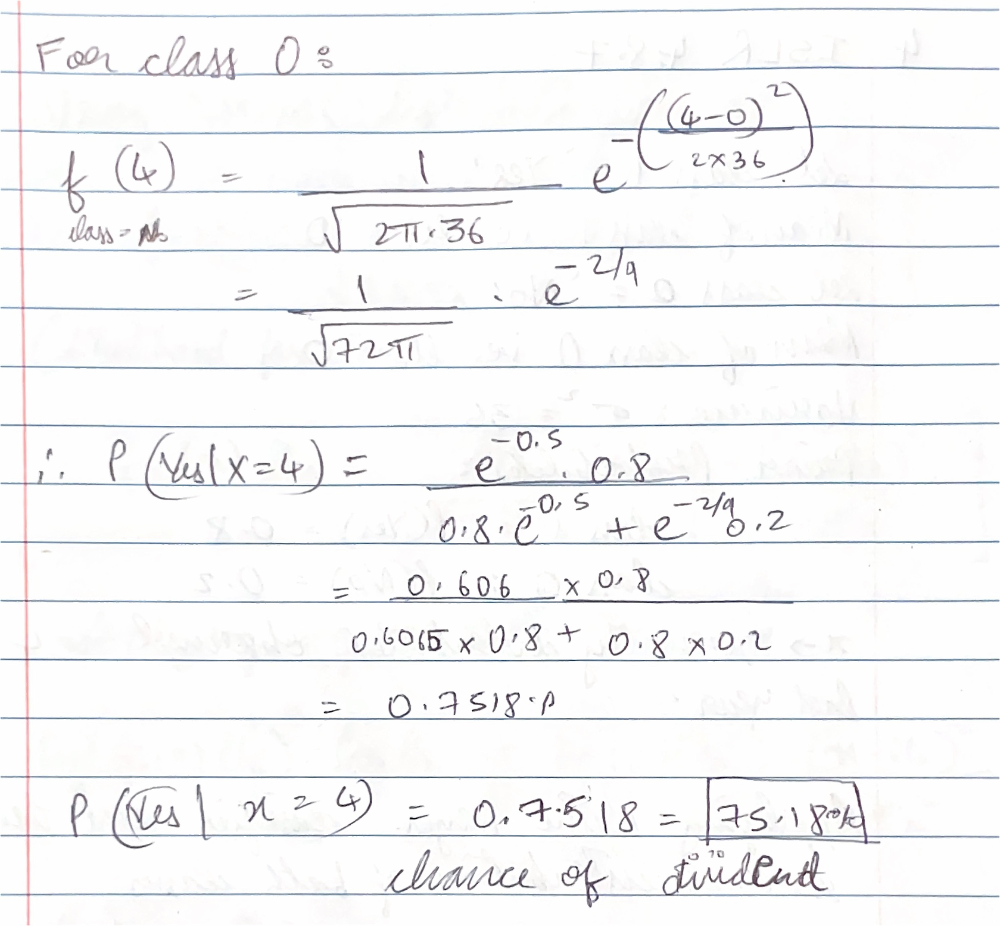

- - -

#### REFERENCES:

1. https://stackoverflow.com/questions/20906474/import-multiple-csv-files-into-pandas-and-concatenate-into-one-dataframe
2. https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html
3. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegressionCV.html
4. https://jwcn-eurasipjournals.springeropen.com/articles/10.1186/s13638-020-1661-4
5. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression
6. https://stackoverflow.com/questions/20906474/import-multiple-csv-files-into-pandas-and-concatenate-into-one-dataframe
7. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html
8. https://stats.stackexchange.com/questions/50807/features-for-time-series-classification#:~:text=Usually%20the%20features%20used%20to,than%20being%20features%20in%20themselves.